# FGM Prevalence and Regional Attitude Comparison, Kenya — v2

This notebook is self-contained: it fits the same survey-weighted BYM2 attitude model using the selected attitude covariates, creates the regional attitude map, regenerates the two adjusted prevalence maps separately, and then produces separate and combined overlays. It does not require a previously generated attitude CSV.

The Kenya data supplied to this project contain 47 admin-1 county boundaries but no DHS cluster coordinates. The attitude model therefore uses the verified county polygon adjacency, normalized DHS weights, age as a flexible RW2 effect, selected fixed covariates, and a BYM2 county effect. Centroid points in overlays are county map symbols, not survey locations.

Part 2 (sections 9–13) adds men's attitudes from the men's recode, with the same model, maps and overlays, and compares women and men.


## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"
survey_year <- 2022
project_root <- if (dir.exists("../02_Data")) ".." else "."
combined_dir <- file.path(project_root,"02_Data","processed",country_iso3,"combined")
prevalence_data_dir <- file.path(project_root,"02_Data","processed",country_iso3,"prevalence")
prevalence_output_dir <- file.path(project_root,"03_Outputs",country_iso3,"FGM_Prevalence")
output_dir <- file.path(project_root,"03_Outputs",country_iso3,"Prevalence_Attitude_Comparison_v2")
shapefile_path <- file.path(project_root,"02_Data","raw",as.character(survey_year),"Survey","boundaries","Kenya Boundaries","shps","sdr_subnational_boundaries.shp")
region_var_shapefile <- "DHSREGEN"
standardize_region <- function(x) {
  x |> as.character() |> toupper() |> stringr::str_replace_all("[^A-Z ]"," ") |> stringr::str_squish()
}
posterior_draws <- 300L
minimum_region_n_display <- 1L
set.seed(20260921)
dir.create(output_dir,recursive=TRUE,showWarnings=FALSE)
# end

## 1. Packages

In [2]:
required_packages <- c("tidyverse","survey","sf","spdep","INLA","ggspatial")
missing_packages <- required_packages[!vapply(required_packages,requireNamespace,logical(1),quietly=TRUE)]
if(length(missing_packages)) stop("Install missing packages: ",paste(missing_packages,collapse=", "))
suppressPackageStartupMessages({library(tidyverse);library(survey);library(sf);library(spdep)})
options(survey.lonely.psu="adjust")
theme_set(ggplot2::theme_minimal(base_size=12))
# end

## 2. Load the attitude sample, prevalence results and Kenya boundaries

In [3]:
attitude <- readRDS(file.path(combined_dir,paste0(country_iso3,"_attitude.rds")))
women_lookup <- readRDS(file.path(prevalence_data_dir,paste0(country_iso3,"_prevalence_self.rds"))) |>
  dplyr::select(resp_id,age,birth_year) |> dplyr::distinct(resp_id,.keep_all=TRUE)
attitude <- attitude |>
  dplyr::left_join(women_lookup,by=c("id"="resp_id")) |>
  dplyr::mutate(
    region=standardize_region(region)
  )
if(anyNA(attitude$age)) stop("Age join failed")

self_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_self.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Women aged 15–49")
daughter_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_daughter.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Girls aged 0–14")

boundaries <- sf::st_read(shapefile_path,quiet=TRUE) |> sf::st_make_valid() |>
  dplyr::mutate(region=standardize_region(.data[[region_var_shapefile]]))
if(length(setdiff(unique(attitude$region),boundaries$region))) stop("Unmatched attitude regions")
cat("Attitude respondents:",nrow(attitude),"\nRegions:",dplyr::n_distinct(attitude$region),"\n")
# end

Attitude respondents: 15890 
Regions: 47 


## 3. Prepare the selected covariates and regional adjacency graph

In [4]:
selected_predictors <- c("own_status","age","education","wealth","religion","ethnicity","urban_rural")
model_data <- attitude |>
  dplyr::mutate(
    own_status=factor(own_status,levels=c(0,1),labels=c("Not cut","Cut")),
    education=factor(education),wealth=factor(wealth),religion=factor(religion),
    ethnicity=factor(ethnicity),urban_rural=factor(urban_rural),age=as.numeric(age)
  ) |>
  dplyr::filter(!is.na(supports_continuation),is.finite(weight),weight>0) |>
  tidyr::drop_na(dplyr::all_of(selected_predictors)) |> droplevels()

region_sample <- model_data |>
  dplyr::group_by(region) |>
  dplyr::summarise(n_unweighted=dplyr::n(),sum_survey_weight=sum(weight),.groups="drop")
region_points <- boundaries |> sf::st_transform(3857) |> sf::st_point_on_surface() |> sf::st_transform(4326)
region_coordinates <- sf::st_coordinates(region_points)
region_lookup <- boundaries |>
  sf::st_drop_geometry() |>
  dplyr::transmute(region,region_id=dplyr::row_number(),lon=region_coordinates[,1],lat=region_coordinates[,2]) |>
  dplyr::left_join(region_sample,by="region")
model_data <- model_data |>
  dplyr::left_join(region_lookup |> dplyr::select(region,region_id),by="region") |>
  dplyr::mutate(age_id=as.integer(age-min(age)+1L),pseudo_weight=weight/mean(weight))
if(anyNA(model_data$region_id)) stop("Region join failed")
neighbors <- spdep::poly2nb(boundaries,row.names=boundaries$region)
adjacency_matrix <- spdep::nb2mat(neighbors,style="B",zero.policy=TRUE)
cat("Model rows:",nrow(model_data),"\nBYM2 regions:",nrow(region_lookup),"\nMean normalized weight:",mean(model_data$pseudo_weight),"\n")
# end

Warning message:
“st_point_on_surface assumes attributes are constant over geometries”


Model rows: 15890 
BYM2 regions: 47 
Mean normalized weight: 1 


## 4. Fit the covariate-adjusted regional BYM2 model

In [5]:
attitude_formula <- supports_continuation ~ own_status + education + wealth + religion +
  ethnicity + urban_rural +
  f(age_id,model="rw2",constr=TRUE,scale.model=TRUE) +
  f(region_id,model="bym2",graph=adjacency_matrix,scale.model=TRUE)

attitude_region_model <- INLA::inla(
  attitude_formula,family="binomial",data=model_data,weights=model_data$pseudo_weight,
  control.predictor=list(compute=TRUE,link=1),
  control.compute=list(dic=TRUE,waic=TRUE,cpo=TRUE,config=TRUE),
  control.inla=list(control.vb=list(enable=FALSE))
)
print(round(attitude_region_model$summary.fixed[,1:5,drop=FALSE],3))
cat("DIC:",attitude_region_model$dic$dic," WAIC:",attitude_region_model$waic$waic,"\n")
# end

                               mean    sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -5.494 0.394     -6.267   -5.494     -4.721
own_statusCut                 1.994 0.156      1.689    1.994      2.299
educationno education         1.730 0.297      1.147    1.730      2.312
educationprimary              1.447 0.259      0.940    1.447      1.954
educationsecondary            0.939 0.259      0.431    0.939      1.446
wealthpoorer                  0.276 0.175     -0.068    0.276      0.619
wealthpoorest                 0.608 0.172      0.271    0.608      0.945
wealthricher                 -0.226 0.202     -0.622   -0.226      0.170
wealthrichest                -0.198 0.245     -0.679   -0.198      0.283
religioncatholic              0.341 0.240     -0.130    0.341      0.811
religionevangelical churches  0.358 0.231     -0.094    0.358      0.810
religionhindu                -0.327 3.168     -6.538   -0.326      5.885
religionislam                 0.650 0.337     -0.01

DIC: 3199.217  WAIC: 3245.315 


## 5. Aggregate posterior probabilities by region

In [6]:
set.seed(20260922)
samples <- INLA::inla.posterior.sample(posterior_draws,attitude_region_model,use.improved.mean=FALSE,skew.corr=FALSE)
latent_names <- rownames(samples[[1L]]$latent)
predictor_rows <- grep("^Predictor:",latent_names)
predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:","",latent_names[predictor_rows])))
if(!anyNA(predictor_numbers)) predictor_rows <- predictor_rows[order(predictor_numbers)]
if(length(predictor_rows)!=nrow(model_data)) stop("Posterior predictors do not align")
rows_by_region <- lapply(region_lookup$region_id,function(i) which(model_data$region_id==i))
region_draws <- vapply(samples,function(draw){
  probability <- stats::plogis(as.numeric(draw$latent[predictor_rows,1L]))
  vapply(rows_by_region,function(rows) stats::weighted.mean(probability[rows],model_data$weight[rows]),numeric(1L))
},numeric(nrow(region_lookup)))
if(is.null(dim(region_draws))) region_draws <- matrix(region_draws,nrow=nrow(region_lookup))
attitude_regions <- region_lookup |>
  dplyr::mutate(adjusted_support=rowMeans(region_draws),
                lower_ci=apply(region_draws,1,stats::quantile,.025,names=FALSE),
                upper_ci=apply(region_draws,1,stats::quantile,.975,names=FALSE))
readr::write_csv(attitude_regions,file.path(output_dir,paste0(country_iso3,"_adjusted_attitude_regions.csv")))
cat("Adjusted regions:",nrow(attitude_regions),"\n")
# end

Adjusted regions: 47 


## 6. Standalone regional attitude map

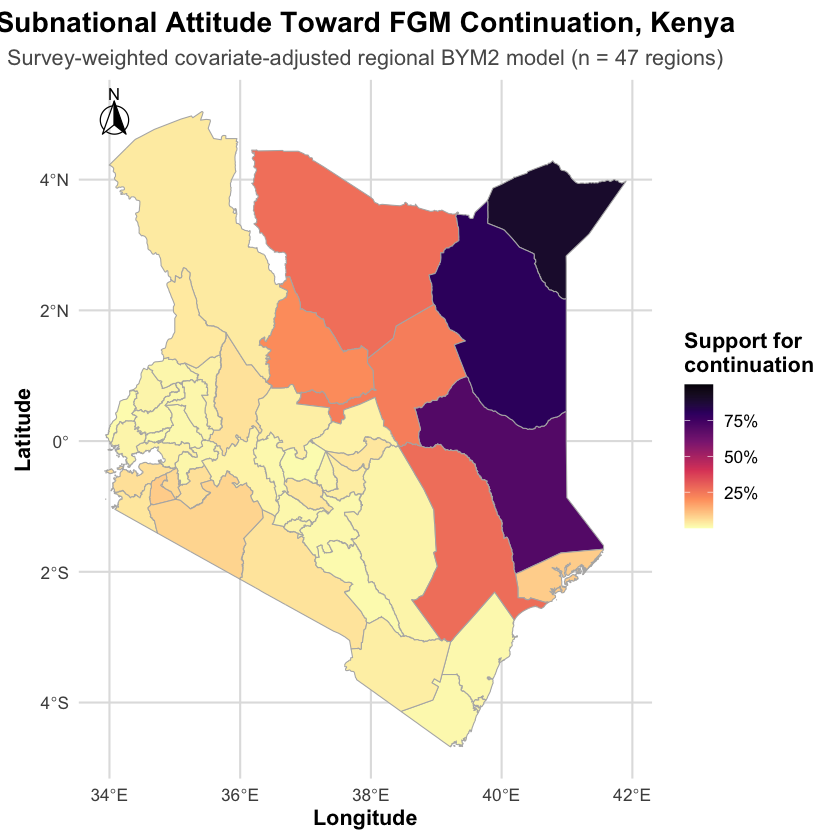

In [7]:
region_plot_data <- attitude_regions |> dplyr::filter(n_unweighted>=minimum_region_n_display)
attitude_map_data <- boundaries |> dplyr::left_join(region_plot_data,by="region")
attitude_region_map <- ggplot2::ggplot(attitude_map_data) +
  ggplot2::geom_sf(ggplot2::aes(fill=adjusted_support),color="grey70",linewidth=.30) +
  ggplot2::scale_fill_viridis_c(name="Support for\ncontinuation",option="magma",direction=-1,
    limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1)) +
  ggspatial::annotation_north_arrow(location="tl",which_north="true",
    style=ggspatial::north_arrow_fancy_orienteering,height=grid::unit(1,"cm"),width=grid::unit(1,"cm")) +
  ggplot2::coord_sf(datum=sf::st_crs(4326)) +
  ggplot2::labs(title=paste("Subnational Attitude Toward FGM Continuation,",country_name),
    subtitle=paste0("Survey-weighted covariate-adjusted regional BYM2 model (n = ",nrow(region_plot_data)," regions)"),
    x="Longitude",y="Latitude") +
  ggplot2::theme_minimal(base_size=13) +
  ggplot2::theme(plot.title=ggplot2::element_text(face="bold",size=17,hjust=.5),
    plot.subtitle=ggplot2::element_text(hjust=.5,color="grey35"),axis.title=ggplot2::element_text(face="bold"),
    legend.title=ggplot2::element_text(face="bold"),panel.grid.major=ggplot2::element_line(color="grey88"))
print(attitude_region_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_attitude_region_adjusted.png")),attitude_region_map,width=11,height=9,dpi=300,bg="white")
# end

## 7. Separate adjusted prevalence maps

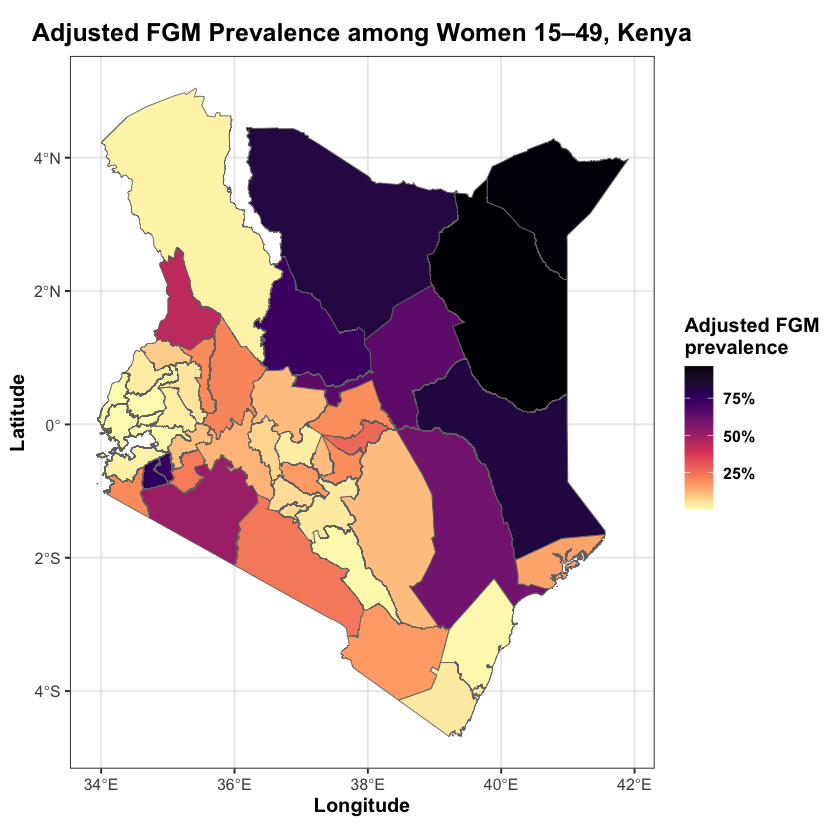

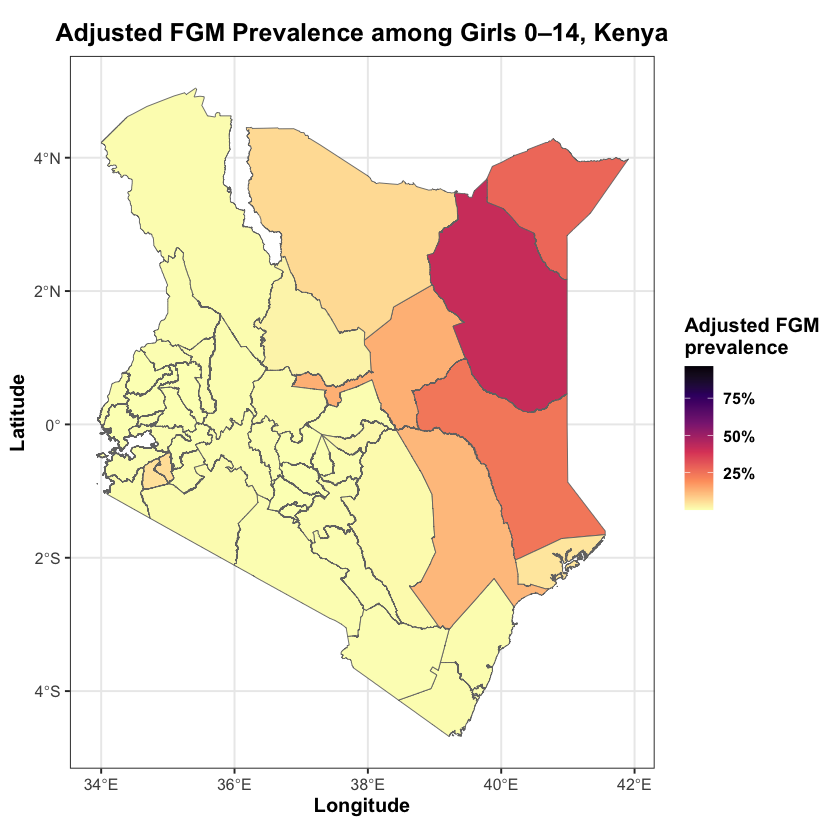

In [8]:
prevalence_long <- dplyr::bind_rows(self_prev,daughter_prev)
prevalence_limits <- range(prevalence_long$prevalence,na.rm=TRUE)
make_prevalence_map <- function(dat,title_text){
  m <- boundaries |> dplyr::left_join(dat,by="region")
  ggplot2::ggplot(m)+ggplot2::geom_sf(ggplot2::aes(fill=prevalence),color="grey45",linewidth=.25)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_prevalence_map <- make_prevalence_map(self_prev,paste("Adjusted FGM Prevalence among Women 15–49,",country_name))
daughter_prevalence_map <- make_prevalence_map(daughter_prev,paste("Adjusted FGM Prevalence among Girls 0–14,",country_name))
print(women_prevalence_map);print(daughter_prevalence_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_women_adjusted.png")),women_prevalence_map,width=9,height=8,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_girls_adjusted.png")),daughter_prevalence_map,width=9,height=8,dpi=300,bg="white")
# end

## 8. Separate overlays and combined comparison

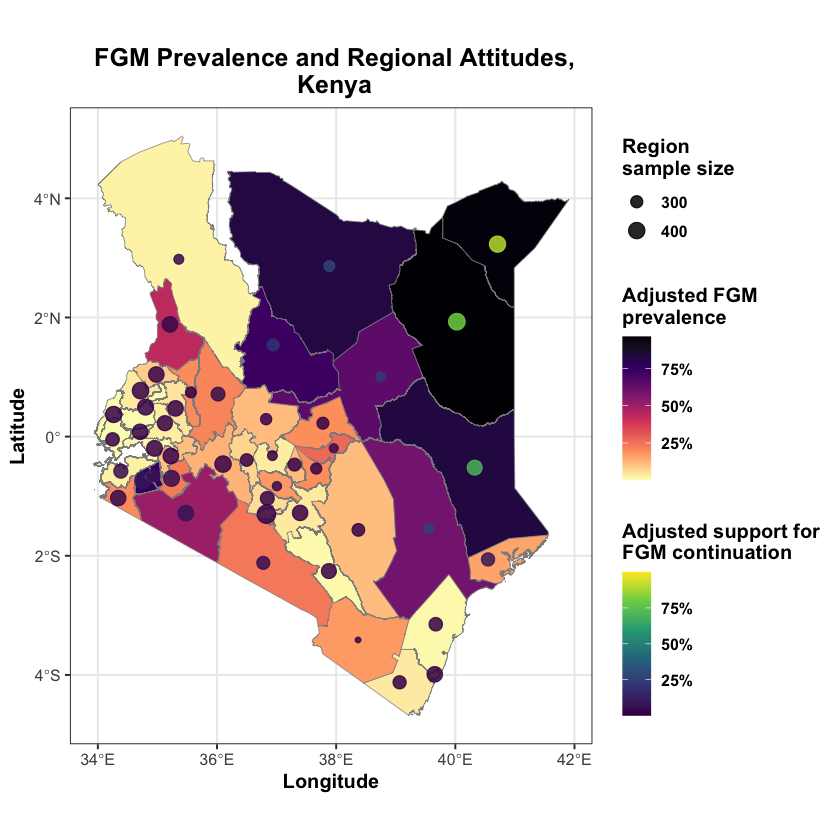

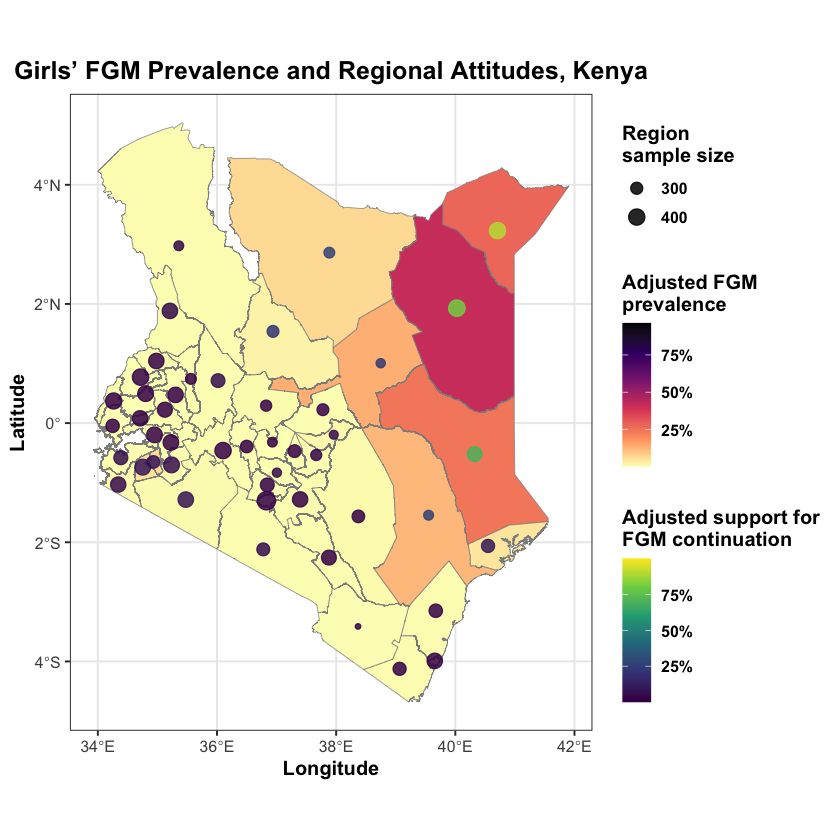

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Girls aged 0–14' in 'mbcsToSbcs': - substituted for – (U+2013)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Women aged 15–49' in 'mbcsToSbcs': - substituted for – (U+2013)”


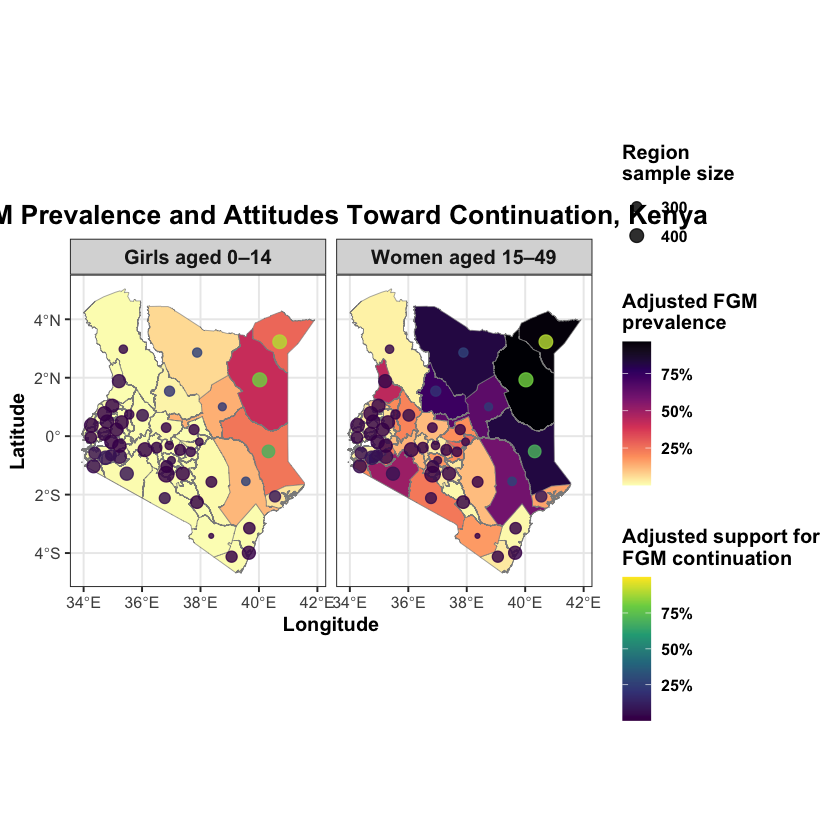

In [9]:
make_overlay <- function(prev,title_text){
  m <- boundaries |> dplyr::left_join(prev,by="region")
  ggplot2::ggplot()+
    ggplot2::geom_sf(data=m,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.2)+
    ggplot2::geom_point(data=region_plot_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.85)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",
      limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1))+
    ggplot2::scale_size_continuous(name="Region\nsample size",range=c(1.2,4.8),breaks=scales::pretty_breaks(3))+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_overlay <- make_overlay(self_prev,paste(" FGM Prevalence and Regional Attitudes,\n",country_name))
girls_overlay <- make_overlay(daughter_prev,paste("Girls’ FGM Prevalence and Regional Attitudes,",country_name))
print(women_overlay);print(girls_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_women_prevalence_attitude.png")),women_overlay,width=11,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_girls_prevalence_attitude.png")),girls_overlay,width=11,height=8.5,dpi=300,bg="white")

map_data <- dplyr::bind_rows(
  boundaries |> dplyr::mutate(panel="Women aged 15–49") |> dplyr::left_join(self_prev,by=c("region","panel")),
  boundaries |> dplyr::mutate(panel="Girls aged 0–14") |> dplyr::left_join(daughter_prev,by=c("region","panel"))
)
point_data <- dplyr::bind_rows(
  region_plot_data |> dplyr::mutate(panel="Women aged 15–49"),
  region_plot_data |> dplyr::mutate(panel="Girls aged 0–14")
)
combined_overlay <- ggplot2::ggplot()+
  ggplot2::geom_sf(data=map_data,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.18)+
  ggplot2::geom_point(data=point_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.82)+
  ggplot2::facet_wrap(~panel,ncol=2)+
  ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
  ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",limits=c(0,1),breaks=c(.25,.5,.75),labels=scales::percent_format(accuracy=1))+
  ggplot2::scale_size_continuous(name="Region\nsample size",range=c(1,4),breaks=scales::pretty_breaks(3))+
  ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=paste("FGM Prevalence and Attitudes Toward Continuation,",country_name),x="Longitude",y="Latitude")+
  ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=16),strip.text=ggplot2::element_text(size=12))
print(combined_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.png")),combined_overlay,width=16,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.pdf")),combined_overlay,width=16,height=8.5,bg="white")
# end

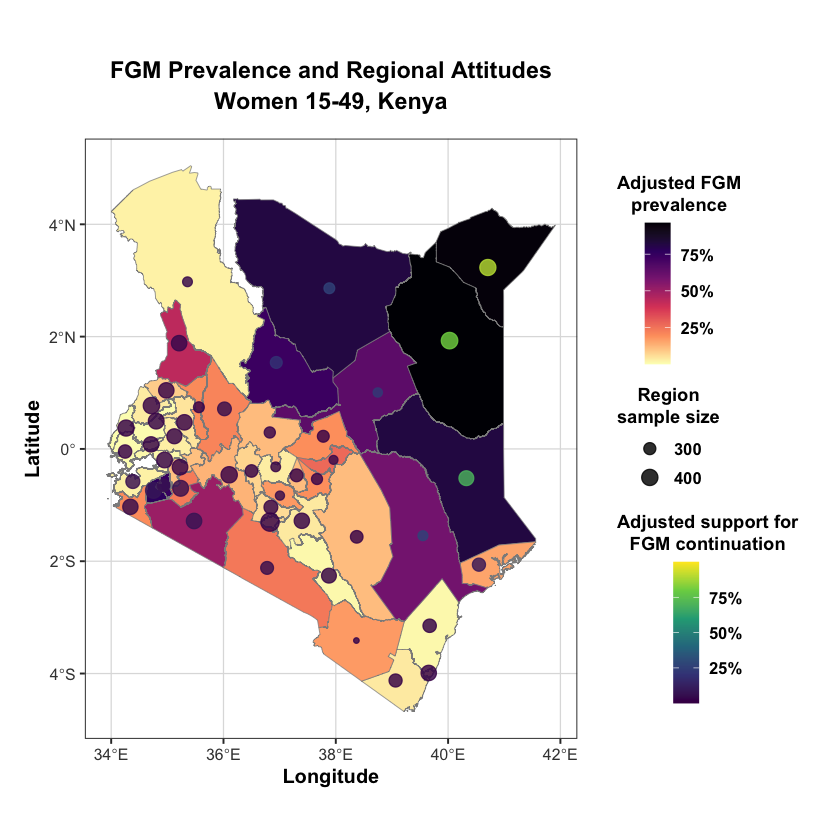

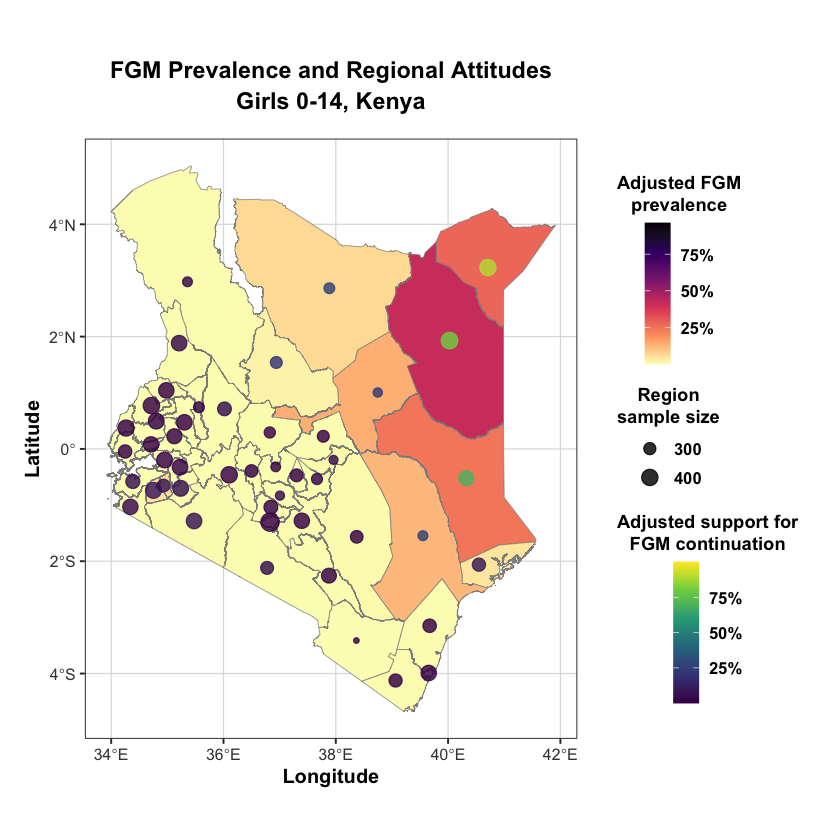

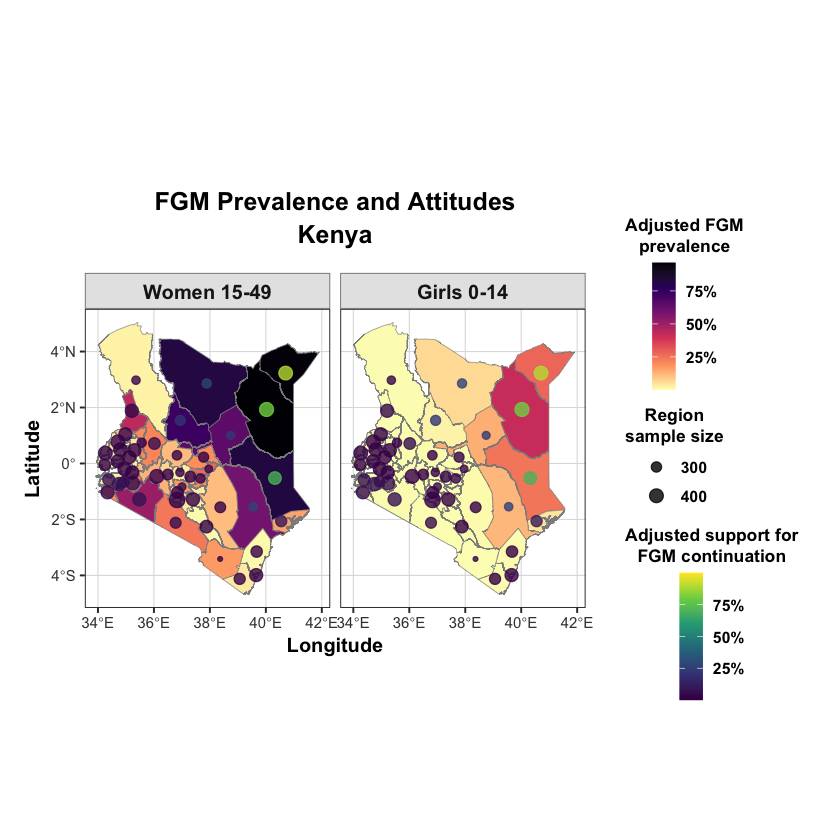

In [10]:
# ============================================================
# 8. Separate overlays and combined comparison
# ============================================================

# Consistent panel labels without special Unicode characters
panel_levels <- c(
  "Women 15-49",
  "Girls 0-14"
)

# ------------------------------------------------------------
# Function for separate prevalence-attitude overlay maps
# ------------------------------------------------------------

make_overlay <- function(
  prevalence_data,
  population_label
) {

  overlay_data <- boundaries |>
    dplyr::left_join(
      prevalence_data |>
        dplyr::select(
          region,
          prevalence
        ),
      by = "region"
    )

  ggplot2::ggplot() +

    # Region-level adjusted prevalence
    ggplot2::geom_sf(
      data = overlay_data,
      ggplot2::aes(
        fill = prevalence
      ),
      color = "grey55",
      linewidth = 0.20
    ) +

    # Region-level adjusted attitude, shown at the polygon centroid
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat,
        color = adjusted_support,
        size = n_unweighted
      ),
      alpha = 0.82
    ) +

    # Prevalence colour scale
    ggplot2::scale_fill_viridis_c(
      name = "Adjusted FGM\nprevalence",
      option = "magma",
      direction = -1,
      limits = prevalence_limits,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 1,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Attitude colour scale
    ggplot2::scale_color_viridis_c(
      name = "Adjusted support for\nFGM continuation",
      option = "viridis",
      limits = c(0, 1),
      breaks = c(
        0.25,
        0.50,
        0.75
      ),
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 3,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Region sample-size scale
    ggplot2::scale_size_continuous(
      name = "Region\nsample size",
      range = c(1.2, 4.8),
      breaks = scales::pretty_breaks(
        n = 3
      ),
      guide = ggplot2::guide_legend(
        order = 2,
        title.position = "top",
        title.hjust = 0.5
      )
    ) +

    ggplot2::coord_sf(
      datum = sf::st_crs(4326)
    ) +

    # Two-line title
    ggplot2::labs(
      title = paste0(
        "FGM Prevalence and Regional Attitudes\n",
        population_label,
        ", ",
        country_name
      ),
      x = "Longitude",
      y = "Latitude"
    ) +

    ggplot2::theme_bw(
      base_size = 12
    ) +

    ggplot2::theme(
      text = ggplot2::element_text(
        face = "bold",
        color = "black"
      ),

      plot.title = ggplot2::element_text(
        face = "bold",
        size = 14,
        hjust = 0.5,
        lineheight = 1.1,
        margin = ggplot2::margin(
          b = 15
        )
      ),

      axis.title = ggplot2::element_text(
        face = "bold",
        size = 12
      ),

      axis.text = ggplot2::element_text(
        face = "bold",
        color = "grey25"
      ),

      legend.position = "right",

      legend.title = ggplot2::element_text(
        face = "bold",
        size = 11,
        lineheight = 1.0
      ),

      legend.text = ggplot2::element_text(
        face = "bold",
        size = 10
      ),

      legend.box = "vertical",

      legend.spacing.y = grid::unit(
        0.45,
        "cm"
      ),

      legend.margin = ggplot2::margin(
        l = 12
      ),

      panel.grid.major = ggplot2::element_line(
        color = "grey87",
        linewidth = 0.35
      ),

      panel.grid.minor = ggplot2::element_blank(),

      plot.margin = ggplot2::margin(
        t = 20,
        r = 25,
        b = 15,
        l = 15
      )
    )
}

# ------------------------------------------------------------
# Separate overlay: women aged 15-49
# ------------------------------------------------------------

women_overlay <- make_overlay(
  prevalence_data = self_prev,
  population_label = "Women 15-49"
)

print(
  women_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.png"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.pdf"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ------------------------------------------------------------
# Separate overlay: girls aged 0-14
# ------------------------------------------------------------

girls_overlay <- make_overlay(
  prevalence_data = daughter_prev,
  population_label = "Girls 0-14"
)

print(
  girls_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.png"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.pdf"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ============================================================
# Prepare the combined two-panel comparison
# ============================================================

women_map_data <- boundaries |>
  dplyr::left_join(
    self_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Women 15-49"
  )

girls_map_data <- boundaries |>
  dplyr::left_join(
    daughter_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Girls 0-14"
  )

map_data <- dplyr::bind_rows(
  women_map_data,
  girls_map_data
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# Repeat the same regional attitude-symbol layer in both panels
point_data <- dplyr::bind_rows(
  region_plot_data |>
    dplyr::mutate(
      panel = "Women 15-49"
    ),
  region_plot_data |>
    dplyr::mutate(
      panel = "Girls 0-14"
    )
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# ============================================================
# Combined two-panel overlay
# ============================================================

combined_overlay <- ggplot2::ggplot() +

  # Region-level adjusted prevalence
  ggplot2::geom_sf(
    data = map_data,
    ggplot2::aes(
      fill = prevalence
    ),
    color = "grey55",
    linewidth = 0.18
  ) +

  # Region-level adjusted attitudes, shown at polygon centroids
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat,
      color = adjusted_support,
      size = n_unweighted
    ),
    alpha = 0.80
  ) +

  # Women first, girls second
  ggplot2::facet_wrap(
    ~panel,
    ncol = 2
  ) +

  # Shared prevalence scale
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted FGM\nprevalence",
    option = "magma",
    direction = -1,
    limits = prevalence_limits,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 1,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared attitude scale
  ggplot2::scale_color_viridis_c(
    name = "Adjusted support for\nFGM continuation",
    option = "viridis",
    limits = c(0, 1),
    breaks = c(
      0.25,
      0.50,
      0.75
    ),
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 3,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared sample-size scale
  ggplot2::scale_size_continuous(
    name = "Region\nsample size",
    range = c(1.0, 4.0),
    breaks = scales::pretty_breaks(
      n = 3
    ),
    guide = ggplot2::guide_legend(
      order = 2,
      title.position = "top",
      title.hjust = 0.5
    )
  ) +

  ggplot2::coord_sf(
    datum = sf::st_crs(4326)
  ) +

  # Brief two-line title
  ggplot2::labs(
    title = paste0(
      "FGM Prevalence and Attitudes\n",
      country_name
    ),
    x = "Longitude",
    y = "Latitude"
  ) +

  ggplot2::theme_bw(
    base_size = 12
  ) +

  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 15,
      hjust = 0.5,
      lineheight = 1.1,
      margin = ggplot2::margin(
        b = 15
      )
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey90",
      color = "grey50",
      linewidth = 0.5
    ),

    axis.title = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "grey25",
      size = 9
    ),

    legend.position = "right",

    legend.title = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      lineheight = 1.0
    ),

    legend.text = ggplot2::element_text(
      face = "bold",
      size = 9.5
    ),

    legend.box = "vertical",

    legend.spacing.y = grid::unit(
      0.35,
      "cm"
    ),

    legend.margin = ggplot2::margin(
      l = 12
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey87",
      linewidth = 0.30
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      t = 20,
      r = 25,
      b = 15,
      l = 15
    )
  )

print(
  combined_overlay
)

# ------------------------------------------------------------
# Save combined comparison
# ------------------------------------------------------------

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.png"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.pdf"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  bg = "white"
)

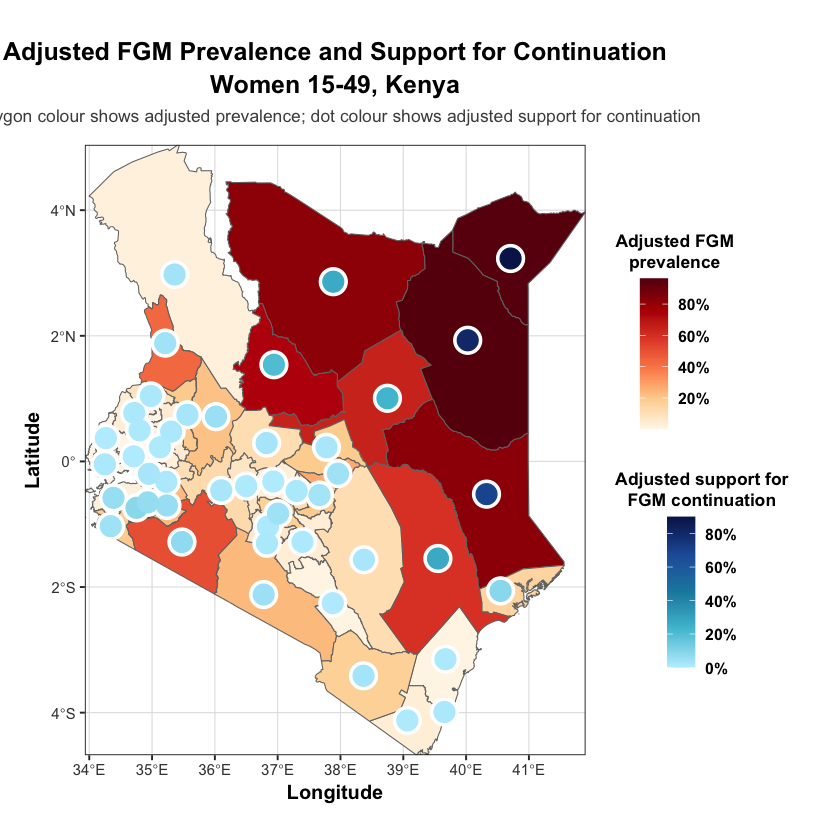

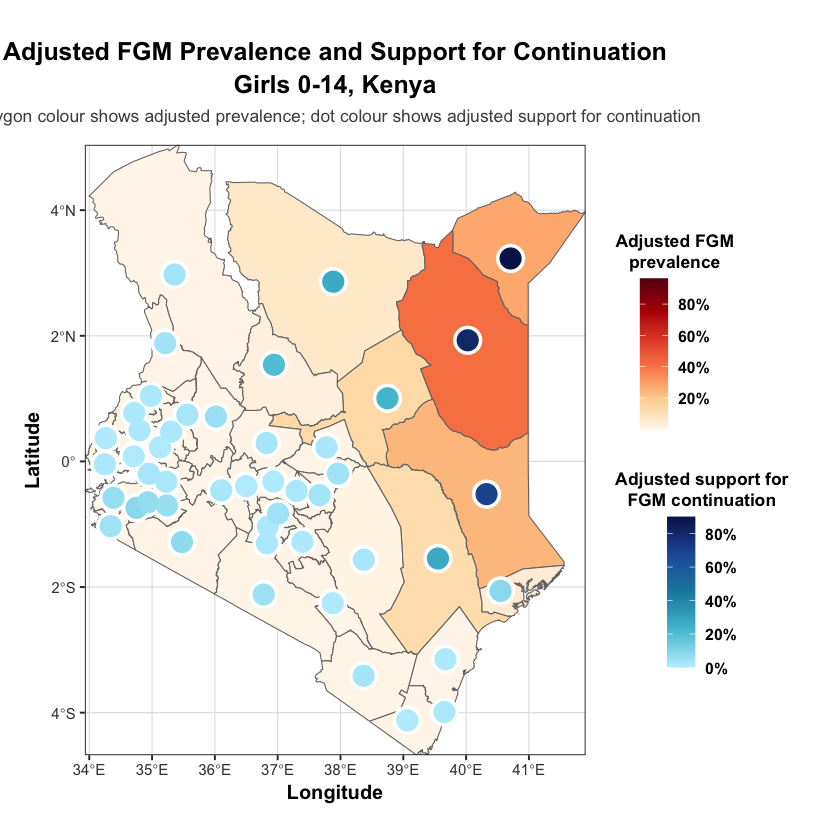

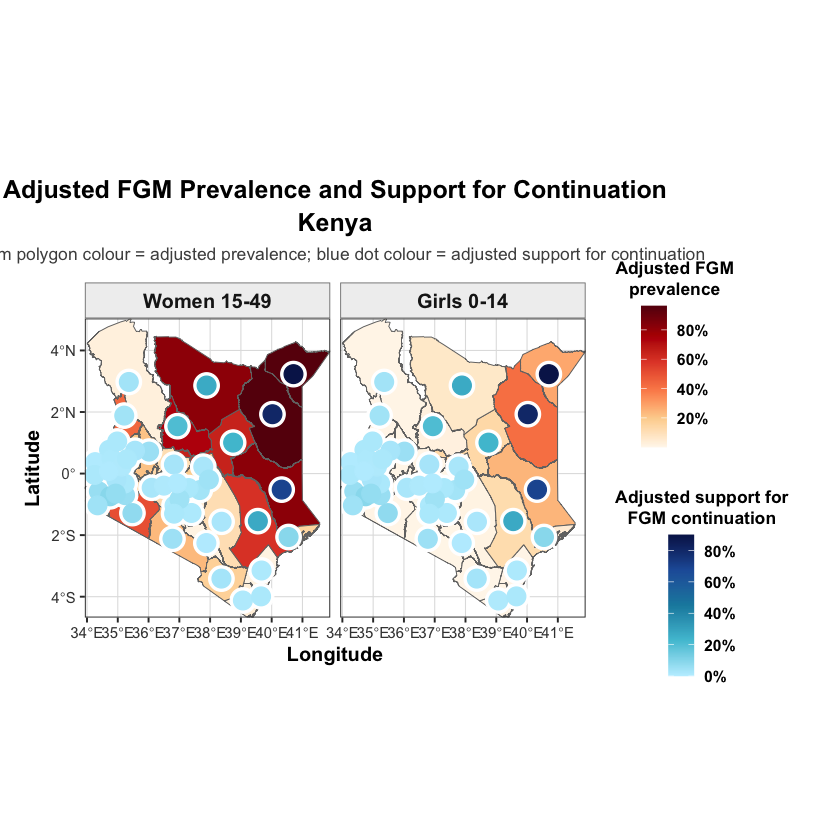

In [11]:
# ============================================================
# 8. Separate overlays and combined comparison
# ============================================================

panel_levels <- c(
  "Women 15-49",
  "Girls 0-14"
)

# ------------------------------------------------------------
# Colour palettes and limits
# ------------------------------------------------------------

# Warm sequential ramp for adjusted FGM prevalence polygons
prevalence_colours <- c(
  "#FFF7EC",
  "#FDD49E",
  "#FC8D59",
  "#E34A33",
  "#B30000",
  "#67000D"
)

# Distinct cool sequential ramp for adjusted support dots
support_colours <- c(
  "#BFEFFF",
  "#4FC3D7",
  "#168AAD",
  "#225EA8",
  "#081D58"
)

# Use the same prevalence scale across women and girls.
prevalence_limits <- range(
  c(
    self_prev$prevalence,
    daughter_prev$prevalence
  ),
  na.rm = TRUE
)

prevalence_breaks <- scales::breaks_pretty(n = 5)(
  prevalence_limits
)

# Kenya support estimates occupy only part of 0-100%.
# Start at zero but focus the scale on the observed range.
maximum_observed_support <- max(
  region_plot_data$adjusted_support,
  na.rm = TRUE
)

support_upper_limit <- min(
  1,
  max(
    0.25,
    ceiling(maximum_observed_support / 0.05) * 0.05
  )
)

support_limits <- c(
  0,
  support_upper_limit
)

support_breaks <- scales::breaks_pretty(n = 5)(
  support_limits
)

# ------------------------------------------------------------
# Shared map theme
# ------------------------------------------------------------

comparison_theme <- ggplot2::theme_bw(
  base_size = 12
) +
  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 15,
      hjust = 0.5,
      lineheight = 1.1,
      margin = ggplot2::margin(b = 7)
    ),

    plot.subtitle = ggplot2::element_text(
      face = "plain",
      size = 10.5,
      hjust = 0.5,
      color = "grey30",
      margin = ggplot2::margin(b = 12)
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey94",
      color = "grey50",
      linewidth = 0.5
    ),

    axis.title = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "grey25",
      size = 9
    ),

    legend.position = "right",

    legend.title = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      lineheight = 1
    ),

    legend.text = ggplot2::element_text(
      face = "bold",
      size = 9.5
    ),

    legend.box = "vertical",

    legend.spacing.y = grid::unit(
      0.45,
      "cm"
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey88",
      linewidth = 0.30
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      t = 18,
      r = 25,
      b = 15,
      l = 15
    )
  )

# ------------------------------------------------------------
# Function for separate overlay maps
# ------------------------------------------------------------

make_overlay <- function(
  prevalence_data,
  population_label
) {

  overlay_data <- boundaries |>
    dplyr::left_join(
      prevalence_data |>
        dplyr::select(
          region,
          prevalence
        ),
      by = "region"
    )

  ggplot2::ggplot() +

    # Adjusted FGM prevalence polygons
    ggplot2::geom_sf(
      data = overlay_data,
      ggplot2::aes(
        fill = prevalence
      ),
      color = "grey45",
      linewidth = 0.30
    ) +

    # White halo behind every attitude dot
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat
      ),
      color = "white",
      size = 7.5,
      alpha = 1
    ) +

    # Solid coloured attitude dots
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat,
        color = adjusted_support
      ),
      size = 5.5,
      alpha = 1
    ) +

    # Prevalence polygon scale
    ggplot2::scale_fill_gradientn(
      name = "Adjusted FGM\nprevalence",
      colours = prevalence_colours,
      limits = prevalence_limits,
      breaks = prevalence_breaks,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 1,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"),
        barwidth = grid::unit(0.60, "cm")
      )
    ) +

    # Support dot scale
    ggplot2::scale_color_gradientn(
      name = "Adjusted support for\nFGM continuation",
      colours = support_colours,
      limits = support_limits,
      breaks = support_breaks,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 2,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"),
        barwidth = grid::unit(0.60, "cm")
      )
    ) +

    ggplot2::coord_sf(
      datum = sf::st_crs(4326),
      expand = FALSE
    ) +

    ggplot2::labs(
      title = paste0(
        "Adjusted FGM Prevalence and Support for Continuation\n",
        population_label,
        ", ",
        country_name
      ),
      subtitle = paste0(
        "Polygon colour shows adjusted prevalence; ",
        "dot colour shows adjusted support for continuation"
      ),
      x = "Longitude",
      y = "Latitude"
    ) +

    comparison_theme
}

# ------------------------------------------------------------
# Separate overlay: women aged 15-49
# ------------------------------------------------------------

women_overlay <- make_overlay(
  prevalence_data = self_prev,
  population_label = "Women 15-49"
)

print(women_overlay)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.png"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.pdf"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ------------------------------------------------------------
# Separate overlay: girls aged 0-14
# ------------------------------------------------------------

girls_overlay <- make_overlay(
  prevalence_data = daughter_prev,
  population_label = "Girls 0-14"
)

print(girls_overlay)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.png"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.pdf"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ============================================================
# Prepare combined two-panel comparison
# ============================================================

women_map_data <- boundaries |>
  dplyr::left_join(
    self_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Women 15-49"
  )

girls_map_data <- boundaries |>
  dplyr::left_join(
    daughter_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Girls 0-14"
  )

map_data <- dplyr::bind_rows(
  women_map_data,
  girls_map_data
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# Repeat the regional support dots in both panels.
point_data <- dplyr::bind_rows(
  region_plot_data |>
    dplyr::mutate(
      panel = "Women 15-49"
    ),

  region_plot_data |>
    dplyr::mutate(
      panel = "Girls 0-14"
    )
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# ============================================================
# Combined two-panel overlay
# ============================================================

combined_overlay <- ggplot2::ggplot() +

  # Adjusted prevalence polygons
  ggplot2::geom_sf(
    data = map_data,
    ggplot2::aes(
      fill = prevalence
    ),
    color = "grey45",
    linewidth = 0.28
  ) +

  # White halo behind the support dots
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat
    ),
    color = "white",
    size = 6.8,
    alpha = 1
  ) +

  # Solid support dots
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat,
      color = adjusted_support
    ),
    size = 4.9,
    alpha = 1
  ) +

  ggplot2::facet_wrap(
    ~panel,
    ncol = 2
  ) +

  # Shared prevalence scale
  ggplot2::scale_fill_gradientn(
    name = "Adjusted FGM\nprevalence",
    colours = prevalence_colours,
    limits = prevalence_limits,
    breaks = prevalence_breaks,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 1,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(3, "cm"),
      barwidth = grid::unit(0.55, "cm")
    )
  ) +

  # Shared support scale
  ggplot2::scale_color_gradientn(
    name = "Adjusted support for\nFGM continuation",
    colours = support_colours,
    limits = support_limits,
    breaks = support_breaks,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 2,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(3, "cm"),
      barwidth = grid::unit(0.55, "cm")
    )
  ) +

  ggplot2::coord_sf(
    datum = sf::st_crs(4326),
    expand = FALSE
  ) +

  ggplot2::labs(
    title = paste0(
      "Adjusted FGM Prevalence and Support for Continuation\n",
      country_name
    ),
    subtitle = paste0(
      "Warm polygon colour = adjusted prevalence; ",
      "blue dot colour = adjusted support for continuation"
    ),
    x = "Longitude",
    y = "Latitude"
  ) +

  comparison_theme

print(combined_overlay)

# ------------------------------------------------------------
# Save combined comparison
# ------------------------------------------------------------

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.png"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.pdf"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  bg = "white"
)

# Part 2: Men's attitudes and FGM prevalence

Sections 9–12 repeat sections 3–8 for men. They use the men's recode prepared by
`00_EDA_DHS_Country_Year_v2.ipynb` (`KEN_attitude_men.rds`), restricted to men aged
15–49 to match the women. The model is the women's model without own FGM status, which
men do not have: age as RW2, education, wealth, religion, ethnicity and residence as
fixed effects, a BYM2 county effect, and normalized DHS weights.

Section 13 compares women's and men's attitudes directly and against prevalence. Men's
dots use one support colour scale shared with the women's, so a colour means the same
level of support in every men's map and in the women-vs-men panels.


## 9. Men: prepare the covariates and fit the regional BYM2 model


In [12]:
men_max_age <- 49  # match the women's 15-49 age range

attitude_men <- readRDS(file.path(combined_dir, paste0(country_iso3, "_attitude_men.rds"))) |>
  dplyr::mutate(region = standardize_region(region), age = as.numeric(age)) |>
  dplyr::filter(age <= men_max_age)
if (length(setdiff(unique(attitude_men$region), boundaries$region))) stop("Unmatched men's regions")

selected_predictors_men <- setdiff(selected_predictors, "own_status")
model_data_men <- attitude_men |>
  dplyr::mutate(
    education = factor(education), wealth = factor(wealth), religion = factor(religion),
    ethnicity = factor(ethnicity), urban_rural = factor(urban_rural)
  ) |>
  dplyr::filter(!is.na(supports_continuation), is.finite(weight), weight > 0) |>
  tidyr::drop_na(dplyr::all_of(selected_predictors_men)) |>
  droplevels()

region_sample_men <- model_data_men |>
  dplyr::group_by(region) |>
  dplyr::summarise(n_unweighted = dplyr::n(), sum_survey_weight = sum(weight), .groups = "drop")
region_lookup_men <- region_lookup |>
  dplyr::select(region, region_id, lon, lat) |>
  dplyr::left_join(region_sample_men, by = "region")
model_data_men <- model_data_men |>
  dplyr::left_join(region_lookup_men |> dplyr::select(region, region_id), by = "region") |>
  dplyr::mutate(age_id = as.integer(age - min(age) + 1L), pseudo_weight = weight / mean(weight))
if (anyNA(model_data_men$region_id)) stop("Men's region join failed")

attitude_formula_men <- supports_continuation ~ education + wealth + religion +
  ethnicity + urban_rural +
  f(age_id, model = "rw2", constr = TRUE, scale.model = TRUE) +
  f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE)

attitude_region_model_men <- INLA::inla(
  attitude_formula_men, family = "binomial", data = model_data_men,
  weights = model_data_men$pseudo_weight,
  control.predictor = list(compute = TRUE, link = 1),
  control.compute = list(dic = TRUE, waic = TRUE, cpo = TRUE, config = TRUE),
  control.inla = list(control.vb = list(enable = FALSE))
)
cat("Men's model rows:", nrow(model_data_men), "\n")
print(round(attitude_region_model_men$summary.fixed[, 1:5, drop = FALSE], 3))
cat("DIC:", attitude_region_model_men$dic$dic, " WAIC:", attitude_region_model_men$waic$waic, "\n")
# end


Men's model rows: 12878 


                               mean     sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -3.609  0.329     -4.255   -3.609     -2.965
educationno education         0.874  0.228      0.427    0.874      1.320
educationprimary              0.185  0.153     -0.116    0.185      0.486
educationsecondary           -0.145  0.150     -0.440   -0.145      0.149
wealthpoorer                  0.134  0.141     -0.142    0.134      0.411
wealthpoorest                 0.428  0.145      0.144    0.428      0.712
wealthricher                 -0.141  0.153     -0.441   -0.141      0.159
wealthrichest                -0.849  0.215     -1.271   -0.849     -0.427
religioncatholic              0.552  0.224      0.112    0.552      0.992
religionevangelical churches  0.485  0.233      0.029    0.485      0.942
religionhindu                -4.738 13.204    -30.631   -4.738     21.154
religionislam                 0.793  0.297      0.211    0.793      1.374
religionno religion/atheists  0.873  0

DIC: 4215.929  WAIC: 8014.66 


## 10. Men: aggregate posterior probabilities by region


In [13]:
set.seed(20260923)
samples_men <- INLA::inla.posterior.sample(posterior_draws, attitude_region_model_men,
                                           use.improved.mean = FALSE, skew.corr = FALSE)
latent_names_men <- rownames(samples_men[[1L]]$latent)
predictor_rows_men <- grep("^Predictor:", latent_names_men)
predictor_numbers_men <- suppressWarnings(as.integer(sub("^Predictor:", "", latent_names_men[predictor_rows_men])))
if (!anyNA(predictor_numbers_men)) predictor_rows_men <- predictor_rows_men[order(predictor_numbers_men)]
if (length(predictor_rows_men) != nrow(model_data_men)) stop("Men's posterior predictors do not align")

rows_by_region_men <- lapply(region_lookup_men$region_id, function(i) which(model_data_men$region_id == i))
region_draws_men <- vapply(samples_men, function(draw) {
  probability <- stats::plogis(as.numeric(draw$latent[predictor_rows_men, 1L]))
  vapply(rows_by_region_men, function(rows) {
    stats::weighted.mean(probability[rows], model_data_men$weight[rows])
  }, numeric(1L))
}, numeric(nrow(region_lookup_men)))
if (is.null(dim(region_draws_men))) region_draws_men <- matrix(region_draws_men, nrow = nrow(region_lookup_men))

attitude_regions_men <- region_lookup_men |>
  dplyr::mutate(adjusted_support = rowMeans(region_draws_men),
                lower_ci = apply(region_draws_men, 1, stats::quantile, .025, names = FALSE),
                upper_ci = apply(region_draws_men, 1, stats::quantile, .975, names = FALSE))
readr::write_csv(attitude_regions_men,
                 file.path(output_dir, paste0(country_iso3, "_adjusted_attitude_regions_men.csv")))
region_plot_data_men <- attitude_regions_men |> dplyr::filter(n_unweighted >= minimum_region_n_display)
cat("Men's adjusted regions:", nrow(attitude_regions_men), "\n")

# One support scale for women's and men's dots, so colours are comparable.
support_upper_limit_shared <- min(1, max(
  0.25,
  ceiling(max(c(region_plot_data$adjusted_support, region_plot_data_men$adjusted_support),
              na.rm = TRUE) / 0.05) * 0.05
))
support_limits_shared <- c(0, support_upper_limit_shared)
support_breaks_shared <- scales::breaks_pretty(n = 5)(support_limits_shared)
cat("Shared support scale: 0 to", scales::percent(support_upper_limit_shared),
    "| women-only scale used in section 8: 0 to", scales::percent(support_upper_limit), "\n")
# end


Men's adjusted regions: 47 


Shared support scale: 0 to 90% | women-only scale used in section 8: 0 to 90% 


## 11. Men: standalone regional attitude map


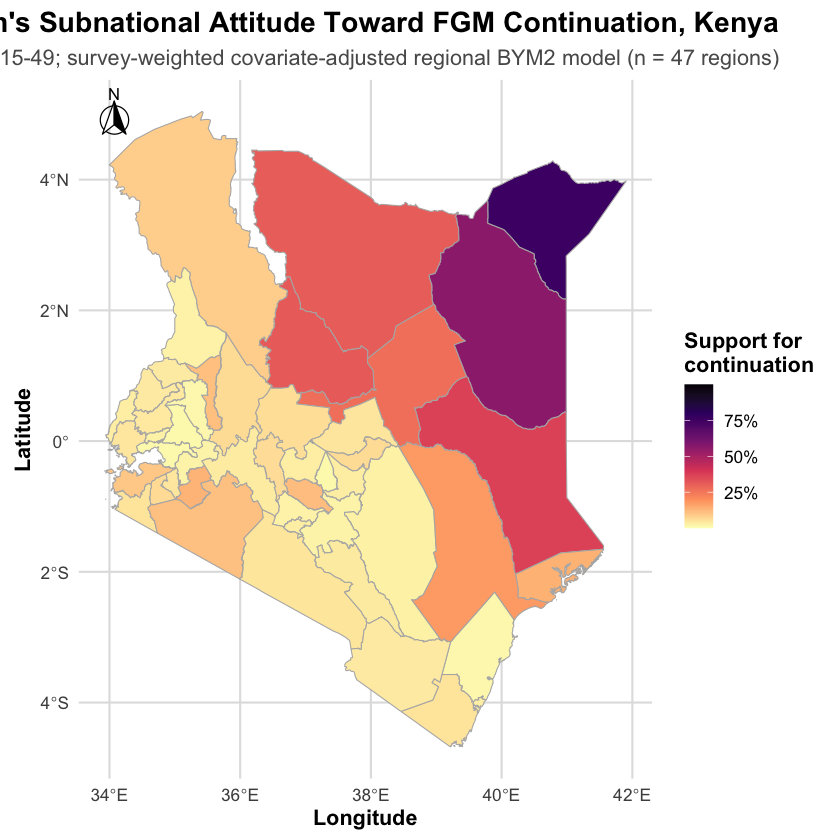

In [14]:
attitude_map_data_men <- boundaries |> dplyr::left_join(region_plot_data_men, by = "region")
attitude_region_map_men <- ggplot2::ggplot(attitude_map_data_men) +
  ggplot2::geom_sf(ggplot2::aes(fill = adjusted_support), color = "grey70", linewidth = .30) +
  ggplot2::scale_fill_viridis_c(name = "Support for\ncontinuation", option = "magma", direction = -1,
    limits = c(0, 1), breaks = c(.25, .50, .75), labels = scales::percent_format(accuracy = 1)) +
  ggspatial::annotation_north_arrow(location = "tl", which_north = "true",
    style = ggspatial::north_arrow_fancy_orienteering,
    height = grid::unit(1, "cm"), width = grid::unit(1, "cm")) +
  ggplot2::coord_sf(datum = sf::st_crs(4326)) +
  ggplot2::labs(title = paste("Men's Subnational Attitude Toward FGM Continuation,", country_name),
    subtitle = paste0("Men 15-49; survey-weighted covariate-adjusted regional BYM2 model (n = ",
                      nrow(region_plot_data_men), " regions)"),
    x = "Longitude", y = "Latitude") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = .5),
    plot.subtitle = ggplot2::element_text(hjust = .5, color = "grey35"),
    axis.title = ggplot2::element_text(face = "bold"),
    legend.title = ggplot2::element_text(face = "bold"),
    panel.grid.major = ggplot2::element_line(color = "grey88"))
print(attitude_region_map_men)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_attitude_region_adjusted_men.png")),
                attitude_region_map_men, width = 11, height = 9, dpi = 300, bg = "white")
# end


## 12. Men: separate overlays and combined comparison

Same layout as section 8, with men's support as the dots over the women's and girls'
prevalence polygons.


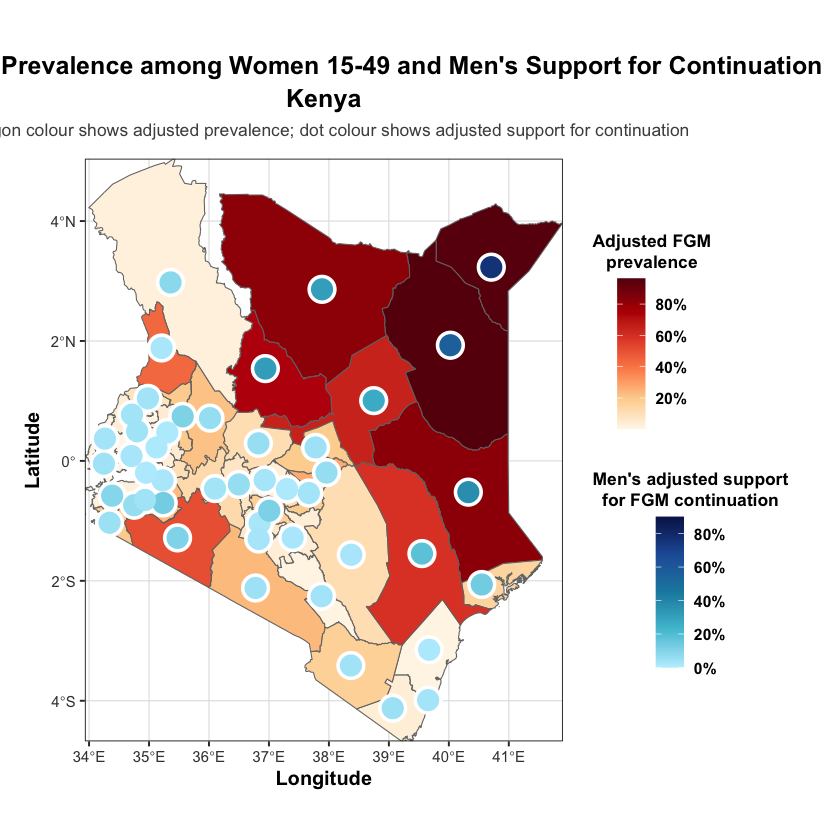

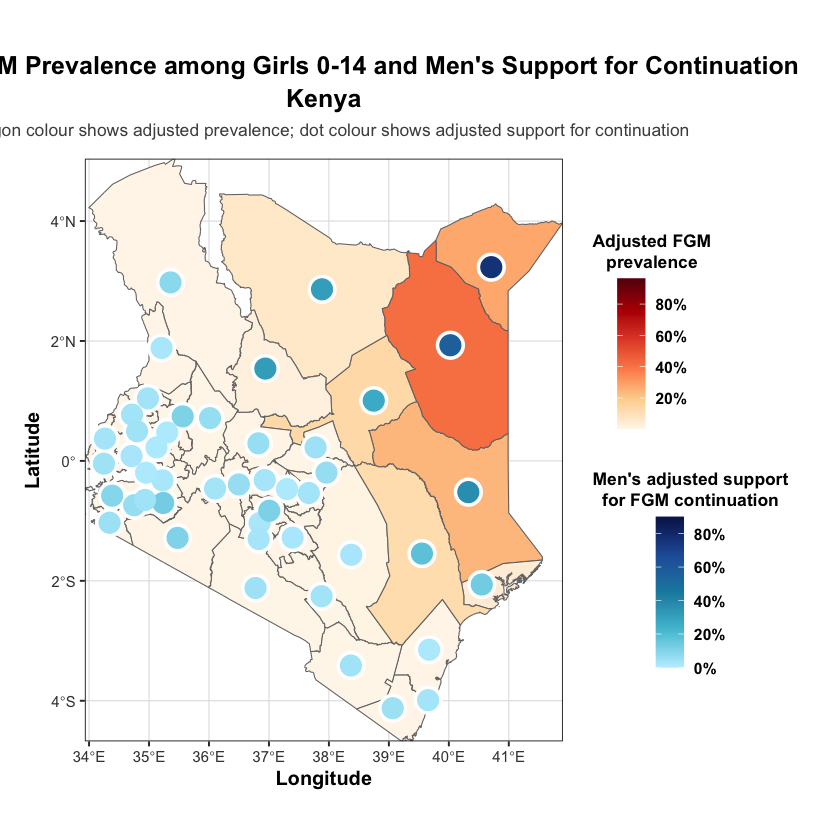

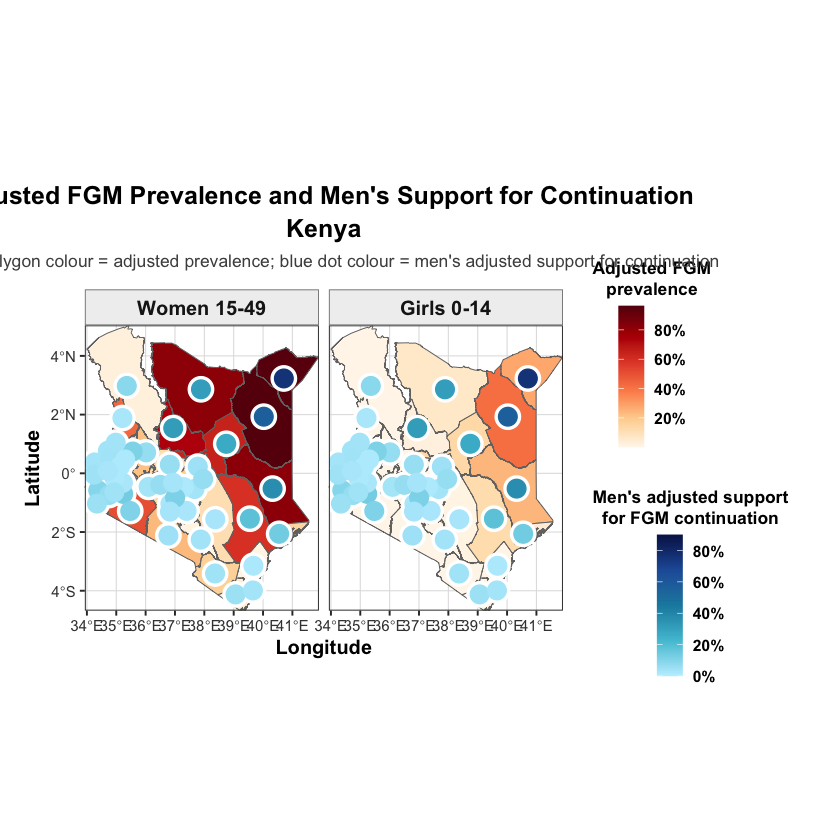

In [15]:
# Section 8's overlay, with the support dots and their scale passed in.
make_support_overlay <- function(prevalence_data, support_points, title_text, support_name) {
  overlay_data <- boundaries |>
    dplyr::left_join(prevalence_data |> dplyr::select(region, prevalence), by = "region")

  ggplot2::ggplot() +
    ggplot2::geom_sf(data = overlay_data, ggplot2::aes(fill = prevalence),
                     color = "grey45", linewidth = 0.30) +
    ggplot2::geom_point(data = support_points, ggplot2::aes(x = lon, y = lat),
                        color = "white", size = 7.5) +
    ggplot2::geom_point(data = support_points, ggplot2::aes(x = lon, y = lat, color = adjusted_support),
                        size = 5.5) +
    ggplot2::scale_fill_gradientn(
      name = "Adjusted FGM\nprevalence", colours = prevalence_colours,
      limits = prevalence_limits, breaks = prevalence_breaks,
      labels = scales::percent_format(accuracy = 1), oob = scales::squish,
      guide = ggplot2::guide_colorbar(order = 1, title.position = "top", title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"), barwidth = grid::unit(0.60, "cm"))
    ) +
    ggplot2::scale_color_gradientn(
      name = support_name, colours = support_colours,
      limits = support_limits_shared, breaks = support_breaks_shared,
      labels = scales::percent_format(accuracy = 1), oob = scales::squish,
      guide = ggplot2::guide_colorbar(order = 2, title.position = "top", title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"), barwidth = grid::unit(0.60, "cm"))
    ) +
    ggplot2::coord_sf(datum = sf::st_crs(4326), expand = FALSE) +
    ggplot2::labs(
      title = title_text,
      subtitle = "Polygon colour shows adjusted prevalence; dot colour shows adjusted support for continuation",
      x = "Longitude", y = "Latitude"
    ) +
    comparison_theme
}

men_support_name <- "Men's adjusted support\nfor FGM continuation"

men_women_overlay <- make_support_overlay(
  self_prev, region_plot_data_men,
  paste0("Adjusted FGM Prevalence among Women 15-49 and Men's Support for Continuation\n", country_name),
  men_support_name
)
men_girls_overlay <- make_support_overlay(
  daughter_prev, region_plot_data_men,
  paste0("Adjusted FGM Prevalence among Girls 0-14 and Men's Support for Continuation\n", country_name),
  men_support_name
)
print(men_women_overlay); print(men_girls_overlay)
for (overlay_name in c("men_women_overlay", "men_girls_overlay")) {
  file_stub <- c(men_women_overlay = "_overlay_women_prevalence_men_attitude",
                 men_girls_overlay = "_overlay_girls_prevalence_men_attitude")[[overlay_name]]
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, file_stub, ".png")),
                  get(overlay_name), width = 13, height = 9, units = "in", dpi = 300, bg = "white")
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, file_stub, ".pdf")),
                  get(overlay_name), width = 13, height = 9, units = "in", bg = "white")
}

point_data_men <- dplyr::bind_rows(
  region_plot_data_men |> dplyr::mutate(panel = "Women 15-49"),
  region_plot_data_men |> dplyr::mutate(panel = "Girls 0-14")
) |>
  dplyr::mutate(panel = factor(panel, levels = panel_levels))

combined_overlay_men <- ggplot2::ggplot() +
  ggplot2::geom_sf(data = map_data, ggplot2::aes(fill = prevalence), color = "grey45", linewidth = 0.28) +
  ggplot2::geom_point(data = point_data_men, ggplot2::aes(x = lon, y = lat), color = "white", size = 6.8) +
  ggplot2::geom_point(data = point_data_men, ggplot2::aes(x = lon, y = lat, color = adjusted_support), size = 4.9) +
  ggplot2::facet_wrap(~panel, ncol = 2) +
  ggplot2::scale_fill_gradientn(
    name = "Adjusted FGM\nprevalence", colours = prevalence_colours,
    limits = prevalence_limits, breaks = prevalence_breaks,
    labels = scales::percent_format(accuracy = 1), oob = scales::squish,
    guide = ggplot2::guide_colorbar(order = 1, title.position = "top", title.hjust = 0.5,
      barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
  ) +
  ggplot2::scale_color_gradientn(
    name = men_support_name, colours = support_colours,
    limits = support_limits_shared, breaks = support_breaks_shared,
    labels = scales::percent_format(accuracy = 1), oob = scales::squish,
    guide = ggplot2::guide_colorbar(order = 2, title.position = "top", title.hjust = 0.5,
      barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326), expand = FALSE) +
  ggplot2::labs(
    title = paste0("Adjusted FGM Prevalence and Men's Support for Continuation\n", country_name),
    subtitle = "Warm polygon colour = adjusted prevalence; blue dot colour = men's adjusted support for continuation",
    x = "Longitude", y = "Latitude"
  ) +
  comparison_theme

print(combined_overlay_men)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_combined_prevalence_men_attitude_overlay.png")),
                combined_overlay_men, width = 17, height = 9, units = "in", dpi = 300, bg = "white")
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_combined_prevalence_men_attitude_overlay.pdf")),
                combined_overlay_men, width = 17, height = 9, units = "in", bg = "white")
# end


## 13. Women's and men's attitudes compared, and against prevalence

- A 2×2 overlay: rows are whose support the dots show (women, men); columns are the
  prevalence polygons (women 15–49, girls 0–14). All four panels share one prevalence
  scale and one support scale.
- A county table of adjusted support for women and men next to adjusted prevalence,
  with Spearman correlations between support and prevalence for each sex.


# A tibble: 5 × 3
  support      compared_with           spearman_rho
  <chr>        <chr>                          <dbl>
1 Women        Prevalence, women 15-49        0.838
2 Women        Prevalence, girls 0-14         0.699
3 Men          Prevalence, women 15-49        0.639
4 Men          Prevalence, girls 0-14         0.644
5 Men vs women Women's support                0.763


# A tibble: 47 × 10
   region  women_support women_lower women_upper men_support men_lower men_upper
   <chr>           <dbl>       <dbl>       <dbl>       <dbl>     <dbl>     <dbl>
 1 WAJIR            80.5        73          87          56.2      46.2      67.7
 2 MANDERA          89.9        84.7        94          75.9      67.5      83.5
 3 GARISSA          69.6        63.9        74.9        36.8      29.6      45  
 4 MARSAB…          26.7        18.8        35.6        31        20.5      43.9
 5 KISII             8.8         6.5        11.3         6.2       3.9       9.4
 6 NYAMIRA           6.4         3.5        10.5         4         1.6       7.8
 7 SAMBURU          20.3        14.5        27.8        31.5      20.9      44.1
 8 ISIOLO           23.4        16          31.5        26.6      17.4      36.3
 9 TANA R…          27          19.2        35.5        17.8      11        26.7
10 NAROK             7.3         5.3         9.5        10.7       8        14.2
11 WEST 

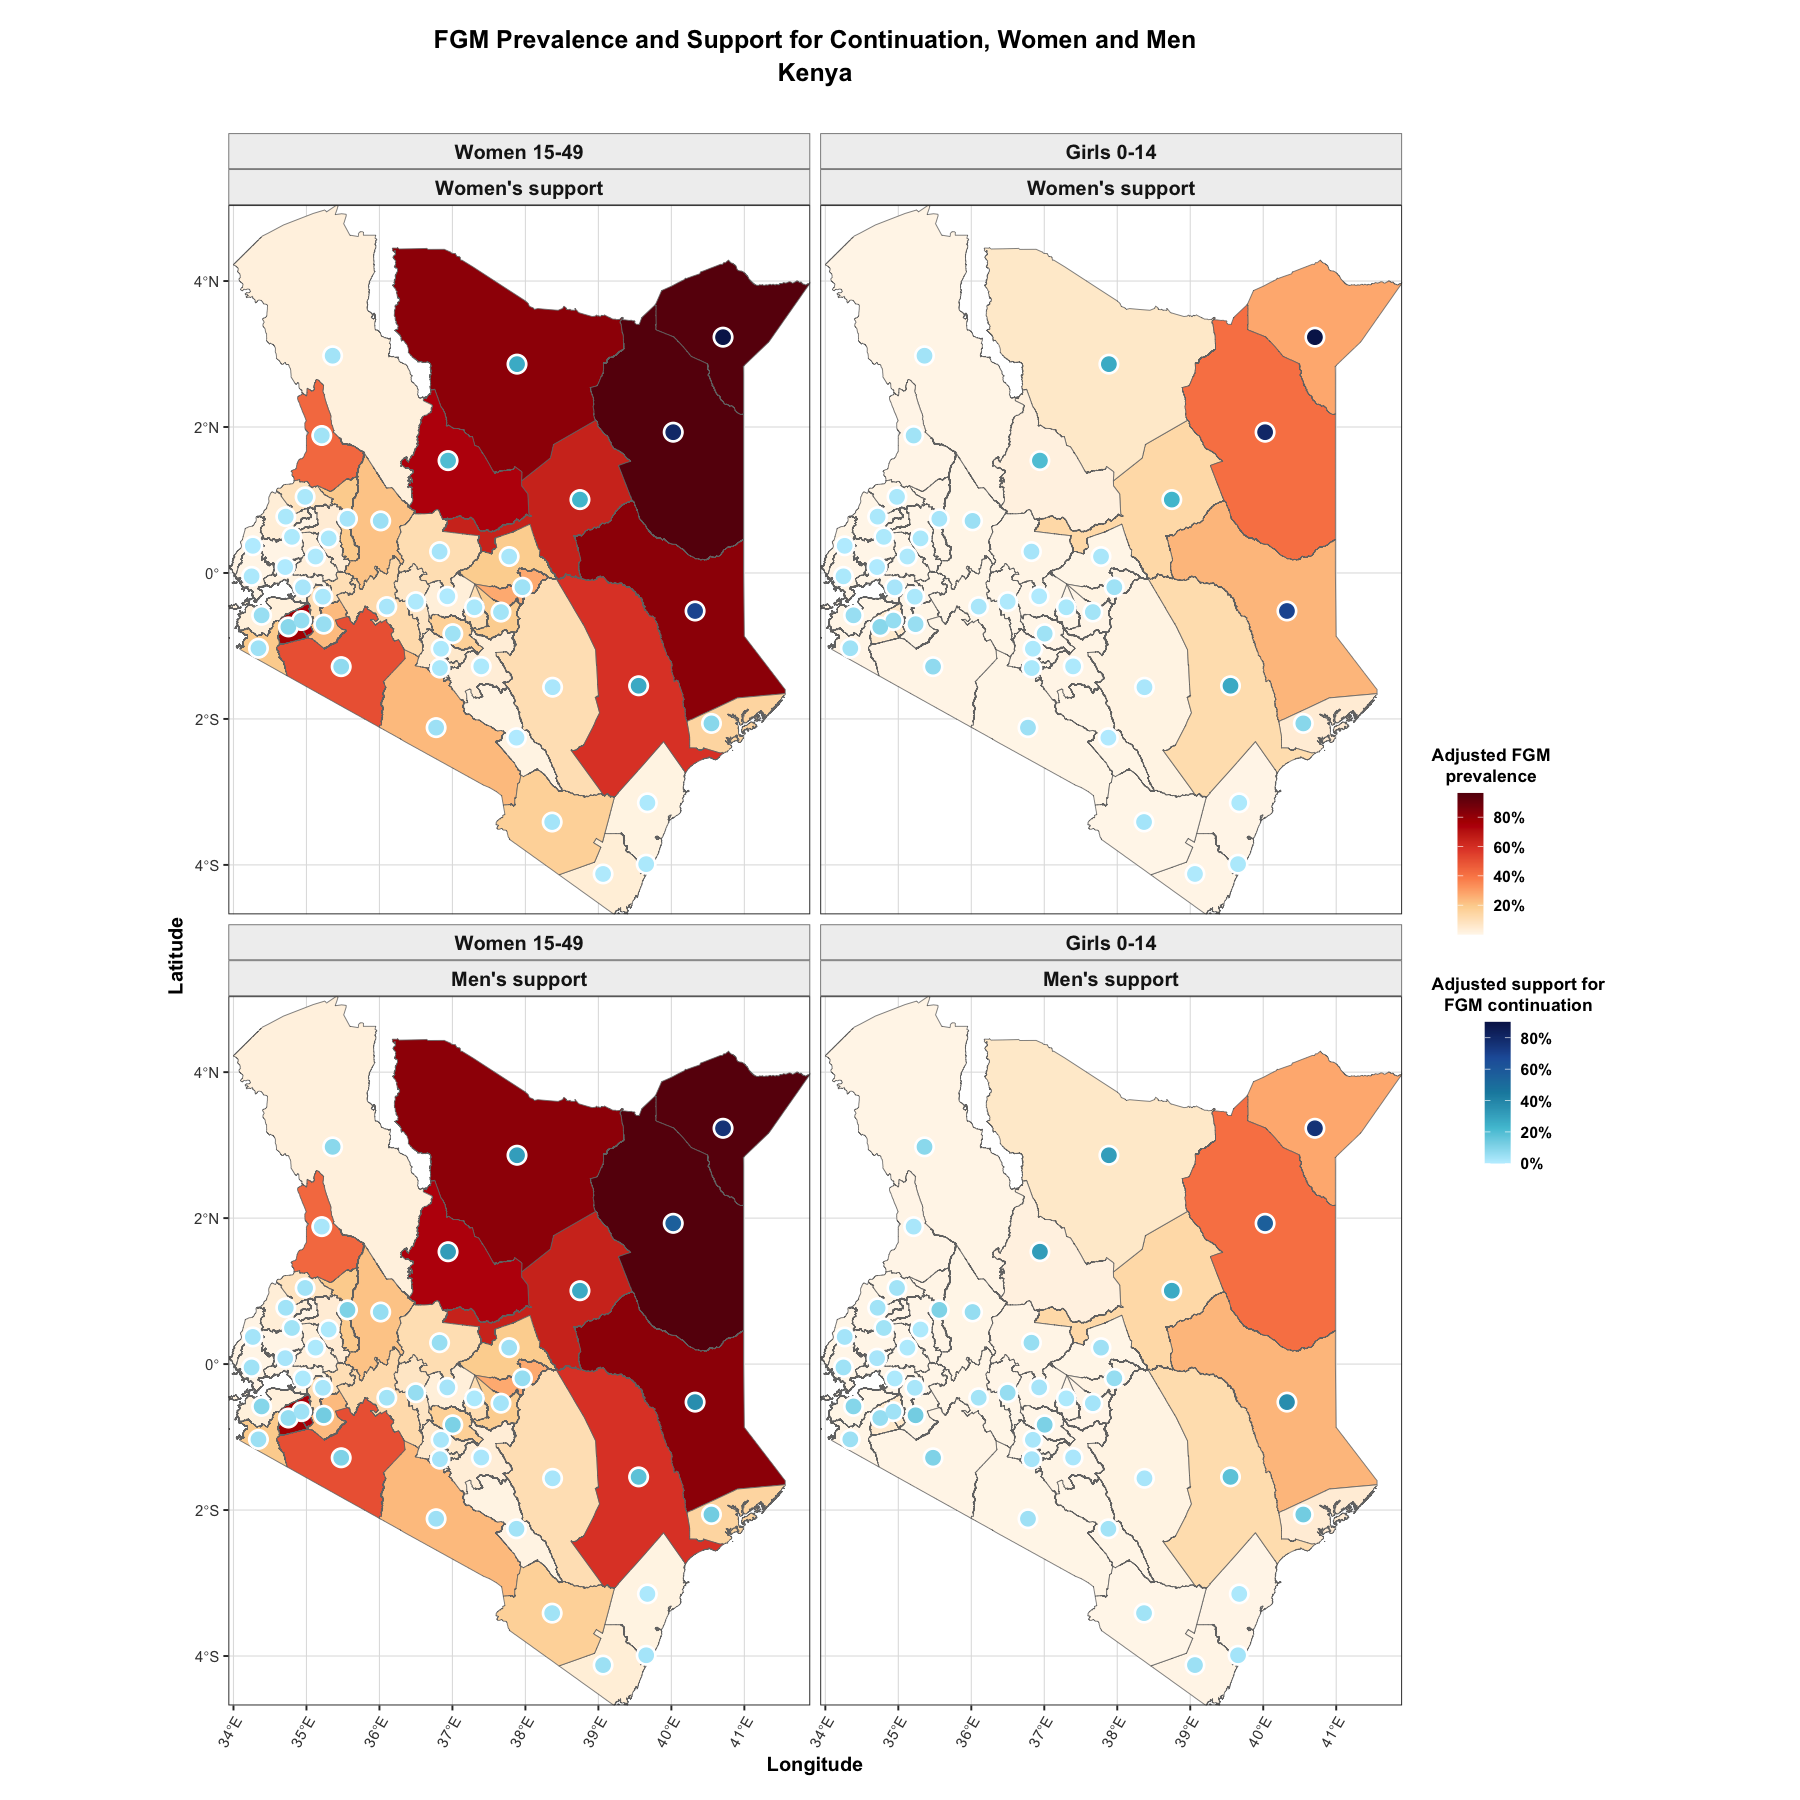

In [16]:
respondent_levels <- c("Women's support", "Men's support")
grid_map_data <- dplyr::bind_rows(
  map_data |> dplyr::mutate(respondent = "Women's support"),
  map_data |> dplyr::mutate(respondent = "Men's support")
) |>
  dplyr::mutate(respondent = factor(respondent, levels = respondent_levels))

grid_point_data <- dplyr::bind_rows(
  point_data |> dplyr::mutate(respondent = "Women's support"),
  point_data_men |> dplyr::mutate(respondent = "Men's support")
) |>
  dplyr::mutate(respondent = factor(respondent, levels = respondent_levels))

women_men_grid <- ggplot2::ggplot() +
  ggplot2::geom_sf(data = grid_map_data, ggplot2::aes(fill = prevalence), color = "grey45", linewidth = 0.22) +
  ggplot2::geom_point(data = grid_point_data, ggplot2::aes(x = lon, y = lat), color = "white", size = 5.2) +
  ggplot2::geom_point(data = grid_point_data, ggplot2::aes(x = lon, y = lat, color = adjusted_support), size = 3.7) +
  # Both labels on top of each map: prevalence group first, whose support below it.
  # dir = "v" fills columns, so women 15-49 is the left column and girls 0-14 the right.
  ggplot2::facet_wrap(~ panel + respondent, ncol = 2, dir = "v") +
  ggplot2::scale_fill_gradientn(
    name = "Adjusted FGM\nprevalence", colours = prevalence_colours,
    limits = prevalence_limits, breaks = prevalence_breaks,
    labels = scales::percent_format(accuracy = 1), oob = scales::squish,
    guide = ggplot2::guide_colorbar(order = 1, title.position = "top", title.hjust = 0.5,
      barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
  ) +
  ggplot2::scale_color_gradientn(
    name = "Adjusted support for\nFGM continuation", colours = support_colours,
    limits = support_limits_shared, breaks = support_breaks_shared,
    labels = scales::percent_format(accuracy = 1), oob = scales::squish,
    guide = ggplot2::guide_colorbar(order = 2, title.position = "top", title.hjust = 0.5,
      barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326), expand = FALSE) +
  ggplot2::labs(
    title = paste0("FGM Prevalence and Support for Continuation, Women and Men\n", country_name),
    subtitle = "",
    x = "Longitude", y = "Latitude"
  ) +
  comparison_theme +
  ggplot2::theme(axis.text.x = ggplot2::element_text(angle = 60, hjust = 1, vjust = 1))

old_plot_options <- options(repr.plot.width = 15, repr.plot.height = 15)
print(women_men_grid)
options(old_plot_options)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_attitude_women_men_grid.png")),
                women_men_grid, width = 15, height = 15, units = "in", dpi = 300, bg = "white")
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_attitude_women_men_grid.pdf")),
                women_men_grid, width = 15, height = 15, units = "in", bg = "white")

county_prevalence_attitude <- tibble::as_tibble(attitude_regions) |>
  dplyr::select(region, women_support = adjusted_support, women_lower = lower_ci, women_upper = upper_ci) |>
  dplyr::left_join(
    attitude_regions_men |>
      dplyr::select(region, men_support = adjusted_support, men_lower = lower_ci, men_upper = upper_ci),
    by = "region"
  ) |>
  dplyr::left_join(self_prev |> dplyr::select(region, prevalence_women = prevalence), by = "region") |>
  dplyr::left_join(daughter_prev |> dplyr::select(region, prevalence_girls = prevalence), by = "region") |>
  dplyr::mutate(men_minus_women = men_support - women_support) |>
  dplyr::arrange(dplyr::desc(prevalence_women))

spearman <- function(x, y) stats::cor(x, y, method = "spearman", use = "complete.obs")
support_prevalence_correlation <- tibble::tibble(
  support = c("Women", "Women", "Men", "Men", "Men vs women"),
  compared_with = c("Prevalence, women 15-49", "Prevalence, girls 0-14",
                    "Prevalence, women 15-49", "Prevalence, girls 0-14", "Women's support"),
  spearman_rho = with(county_prevalence_attitude, c(
    spearman(women_support, prevalence_women), spearman(women_support, prevalence_girls),
    spearman(men_support, prevalence_women), spearman(men_support, prevalence_girls),
    spearman(men_support, women_support)
  ))
)
readr::write_csv(county_prevalence_attitude,
                 file.path(output_dir, paste0(country_iso3, "_county_prevalence_attitude_women_men.csv")))
readr::write_csv(support_prevalence_correlation,
                 file.path(output_dir, paste0(country_iso3, "_support_prevalence_correlation_women_men.csv")))

print(support_prevalence_correlation)
county_prevalence_attitude |>
  dplyr::mutate(dplyr::across(-region, ~ round(100 * .x, 1))) |>
  print(n = Inf)
# end


### Separate women's and men's figures

The 2×2 grid split into one figure per sex: prevalence among women 15–49 and girls 0–14,
with the dots showing that sex's support. Both figures use the same scales as the grid,
so they can be compared side by side.


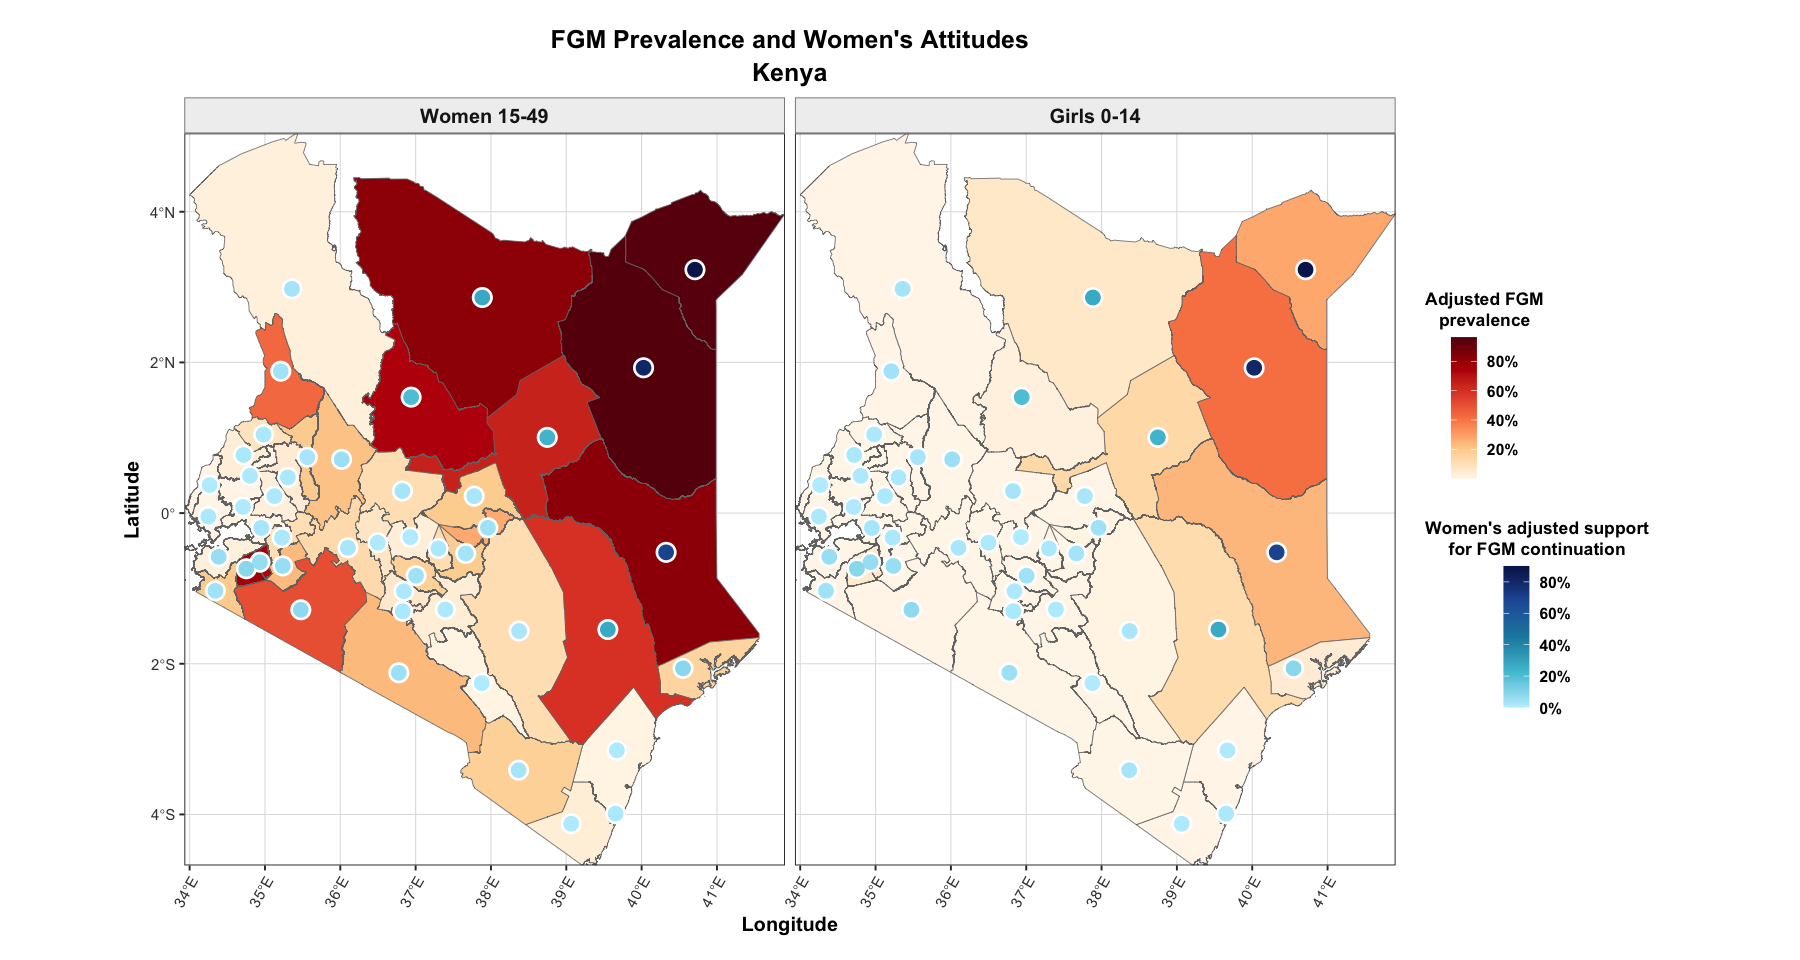

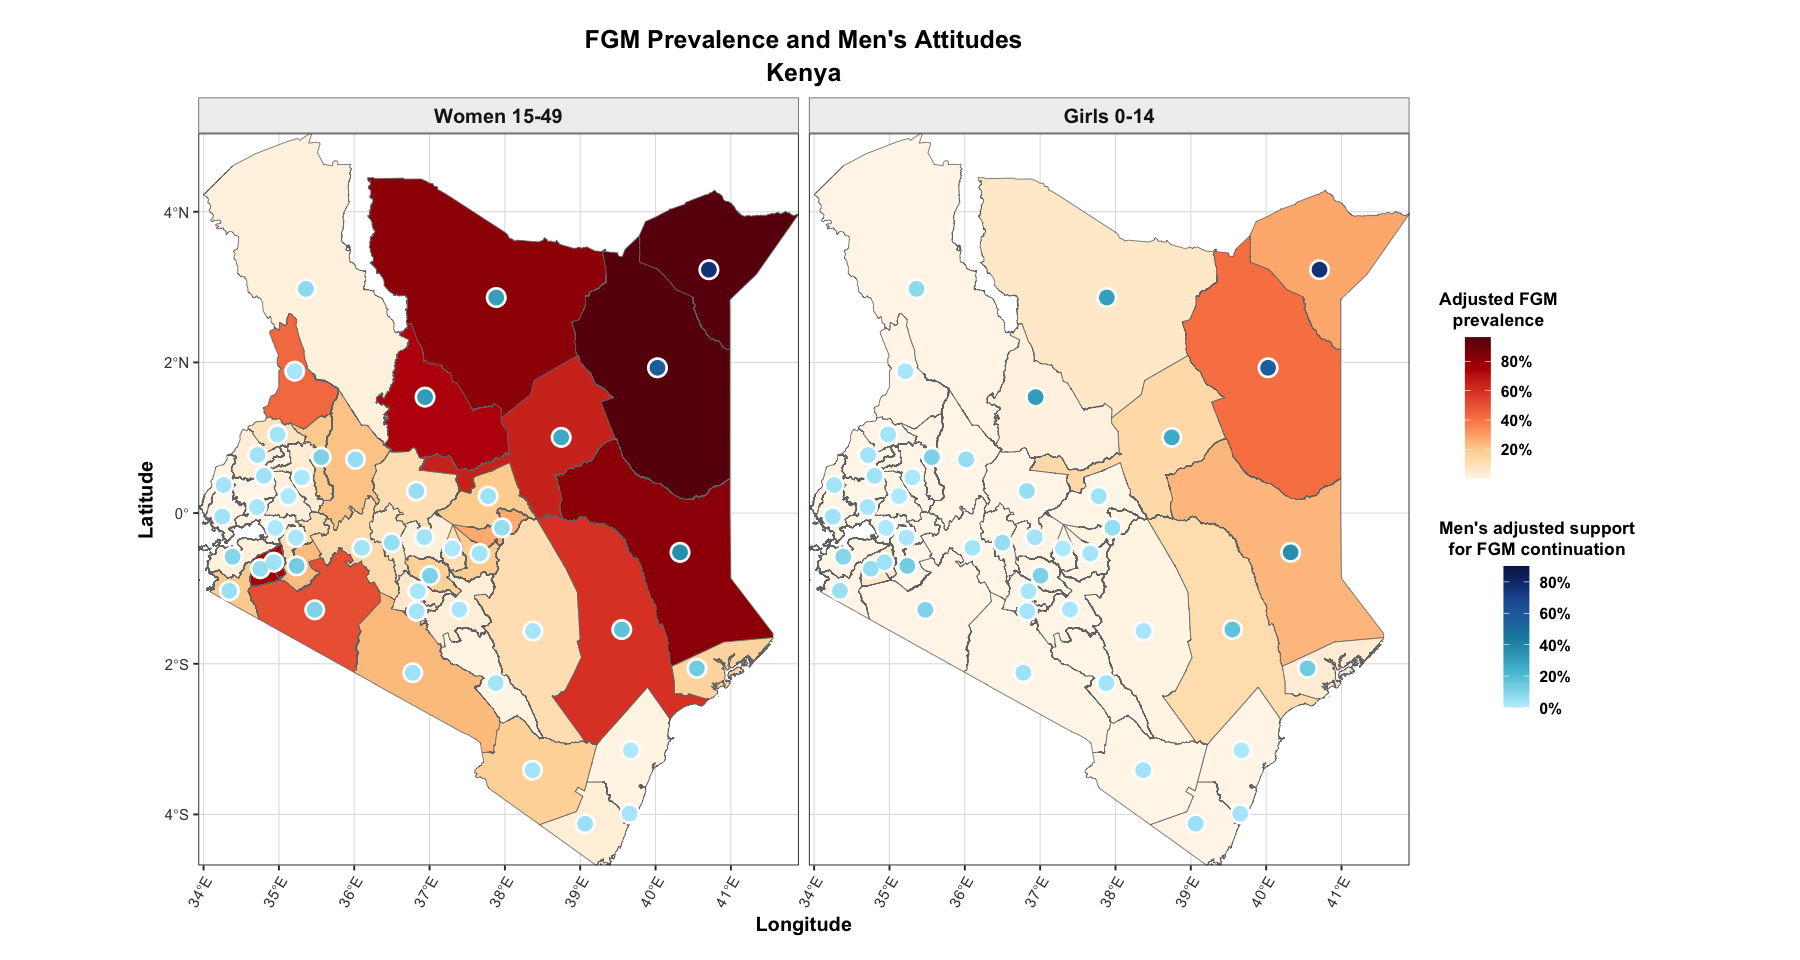

In [38]:
make_attitude_panels <- function(respondent_label, sex_label) {
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = map_data, ggplot2::aes(fill = prevalence), color = "grey45", linewidth = 0.22) +
    ggplot2::geom_point(data = grid_point_data |> dplyr::filter(respondent == respondent_label),
                        ggplot2::aes(x = lon, y = lat), color = "white", size = 5.2) +
    ggplot2::geom_point(data = grid_point_data |> dplyr::filter(respondent == respondent_label),
                        ggplot2::aes(x = lon, y = lat, color = adjusted_support), size = 3.7) +
    ggplot2::facet_wrap(~panel, ncol = 2) +
    ggplot2::scale_fill_gradientn(
      name = "Adjusted FGM\nprevalence", colours = prevalence_colours,
      limits = prevalence_limits, breaks = prevalence_breaks,
      labels = scales::percent_format(accuracy = 1), oob = scales::squish,
      guide = ggplot2::guide_colorbar(order = 1, title.position = "top", title.hjust = 0.5,
        barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
    ) +
    ggplot2::scale_color_gradientn(
      name = paste0(sex_label, "'s adjusted support\nfor FGM continuation"), colours = support_colours,
      limits = support_limits_shared, breaks = support_breaks_shared,
      labels = scales::percent_format(accuracy = 1), oob = scales::squish,
      guide = ggplot2::guide_colorbar(order = 2, title.position = "top", title.hjust = 0.5,
        barheight = grid::unit(3, "cm"), barwidth = grid::unit(0.55, "cm"))
    ) +
    ggplot2::coord_sf(datum = sf::st_crs(4326), expand = FALSE) +
    ggplot2::labs(
      title = paste0("FGM Prevalence and ", sex_label, "'s Attitudes\n", country_name),
      # subtitle = paste0("Polygons: adjusted prevalence. Dots: ", tolower(sex_label),
      #                   "'s adjusted support for continuation (", tolower(sex_label), " 15-49)."),
      x = "Longitude", y = "Latitude"
    ) +
    comparison_theme +
    ggplot2::theme(axis.text.x = ggplot2::element_text(angle = 60, hjust = 1, vjust = 1))
}

women_attitude_panels <- make_attitude_panels("Women's support", "Women")
men_attitude_panels   <- make_attitude_panels("Men's support", "Men")

old_plot_options <- options(repr.plot.width = 15, repr.plot.height = 8)
print(women_attitude_panels)
print(men_attitude_panels)
options(old_plot_options)

for (sex_stub in c("women", "men")) {
  panel_plot <- if (sex_stub == "women") women_attitude_panels else men_attitude_panels
  file_stub <- paste0(country_iso3, "_prevalence_", sex_stub, "_attitude_panels")
  ggplot2::ggsave(file.path(output_dir, paste0(file_stub, ".png")),
                  panel_plot, width = 15, height = 8, units = "in", dpi = 300, bg = "white")
  ggplot2::ggsave(file.path(output_dir, paste0(file_stub, ".pdf")),
                  panel_plot, width = 15, height = 8, units = "in", bg = "white")
}
# end


## Interpretation

The prevalence polygons and attitude symbols are related but different outcomes. Polygon colour represents covariate-adjusted FGM prevalence among women or girls. Point colour represents covariate-adjusted support for continuing FGM among interviewed women aggregated within each region, while point size represents the regional attitude sample. Points are placed at polygon centroids only as map symbols; they are not DHS survey locations. The same symbol layer and scales are used in both overlays. Spatial coincidence is descriptive, not causal.

The men's maps (sections 9–12) read the same way, with dots showing support among men aged 15–49 with a known answer. Men's dots use one support scale shared with the women's dots in section 13; the women-only overlays in section 8 keep their own scale. Women's and men's adjusted models differ by one covariate (own FGM status, which men do not have). Women's and men's support are compared on a design-based basis in `FGM_Attitudinal_Incidence_v2.ipynb`, section 24.


In [18]:
cat("Completed. Outputs saved to:",normalizePath(output_dir,mustWork=FALSE),"\n")
cat("Standalone maps: regional attitude, women prevalence, girls prevalence.\n")
cat("Overlay maps: women, girls, and combined two-panel comparison.\n")
cat("Men: standalone attitude map, overlays on women's and girls' prevalence, combined overlay; women-vs-men grid and county table.\n")
# end


Completed. Outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/03_Outputs/KEN/Prevalence_Attitude_Comparison_v2 


Standalone maps: regional attitude, women prevalence, girls prevalence.


Overlay maps: women, girls, and combined two-panel comparison.


Men: standalone attitude map, overlays on women's and girls' prevalence, combined overlay; women-vs-men grid and county table.
